In [2]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pyarrow.parquet as pq
from torch.utils.data import DataLoader, IterableDataset
import math
import random
from utils.models import *
from utils.train_test import *
from utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec
torch.set_float32_matmul_precision('high')
# --- 1. Configurações e Imports dos Modelos ---
# (Certifique-se de que as classes dos modelos estejam definidas ou importadas aqui)
# from models import convnext_tiny_1d, resnet50_1d 

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 13683
MAX_LEN = 512
NUM_FEATURES = 4
BATCH_SIZE = 2048 
base_type_data = "species"
# Caminhos dos seus Melhores Modelos (Atualize estes caminhos!)
PATH_RESNET = f"../cnn_kraken_{base_type_data}/checkpoints/best_resnet_classifier__fast_phase4.pt" # Exemplo: seu melhor checkpoint da ResNet
PATH_CONVNEXT_zero = f"./checkpoint_{base_type_data}_conv_zero/best_convnext_phase3_restarts_v2.pt" # Seu atual campeão
PATH_CONVNEXT_transfer =  f"./checkpoint_transfer_{base_type_data}_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine =  f"./checkpoint_transfer_{base_type_data}_conv/finetune_noise_7.pt"
PATH_RESNET_fine = f"./checkpoint_finetune_resnet/finetune_noise_14.pt"

# --- 2. Dataset de Teste (Reutilizando sua classe CPU otimizada) ---
# Copie a classe ParquetCPUDataset aqui se ela não estiver no escopo
# (Assumindo que ela já foi definida nas células anteriores)

fs = fsspec.filesystem('file')
test_file_paths = fs.glob(os.path.join(f"./processed_kraken_{base_type_data}_splited_parquet/test", '*.parquet'))




In [3]:
from scipy.stats import wilcoxon

SEED = 42
N_REPEATS = 5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [4]:
from utils.dna_dataset_2 import DaskCuDFIntegerDataset

# Parâmetros de configuração
NUM_CLASSES = 13683
#NUM_CLASSES = 2702
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 8192
#BATCH_SIZE = 496
NUM_WORKERS = 0
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'
PREFETCH_FACTOR = None
base_type_data = "species"
#base_type_data = "genus"
# Get Parquet file paths for the splits
fs = fsspec.filesystem('file')
base_output_directory = f"./processed_kraken_{base_type_data}_splited_parquet"
#base_output_directory = "./synthetic_splited_dataset"
train_dir = os.path.join(base_output_directory, "train")
test_dir = os.path.join(base_output_directory, "test")
val_dir = os.path.join(base_output_directory, "validation")
train_file_paths = fs.glob(os.path.join(train_dir, '*.parquet'))
test_file_paths = fs.glob(os.path.join(test_dir, '*.parquet'))
val_file_paths = fs.glob(os.path.join(val_dir, '*.parquet'))
print(f"Found {len(train_file_paths)} train files, {len(test_file_paths)} test files, {len(val_file_paths)} validation files.")


print(f"Configurando DataLoader com {NUM_WORKERS} workers e prefetch de {PREFETCH_FACTOR} lotes.")


test_dataset = DaskCuDFIntegerDataset(
    test_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)



test_loader = DataLoader(
    test_dataset,
    num_workers=NUM_WORKERS,
    pin_memory=False,
    prefetch_factor=PREFETCH_FACTOR,
    batch_size=None 
)

print("PyTorch DataLoaders criados.")



Found 256 train files, 256 test files, 256 validation files.
Configurando DataLoader com 0 workers e prefetch de None lotes.
PyTorch DataLoaders criados.


In [5]:
from utils.models import *


In [6]:
models = [
    {
        "model_name":"ConvNext finetuned",
        "path":PATH_CONVNEXT_fine,
        "type":"CONVNEXT_FINE"
        
    },
    {
        "model_name":"ConvNext from scratch",
        "path":PATH_CONVNEXT_zero,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ConvNext transfer from genus",
        "path":PATH_CONVNEXT_transfer,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ResNet50",
        "path":PATH_RESNET,
        "type":"RESNET"
    },
    {
        "model_name":"ResNet50_finetuned",
        "path":PATH_RESNET_fine,
        "type":"RESNET_FINE"
    },
]

In [7]:
def load_model(model_dict):
    # 1. Instanciação do Modelo Base
    if "CONVNEXT" in model_dict["type"]:
        dropout = 0.7 if model_dict["type"] == "CONVNEXT_FINE" else 0.5
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=dropout)
    elif "RESNET" in model_dict["type"]:
        model = resnet50_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=0.5)
    else:
        raise ValueError(f"Tipo de modelo desconhecido: {model_dict['type']}")

    # 2. Carregamento dos Pesos no modelo 'bruto'
    # Usar map_location garante que os pesos caiam no lugar certo desde o início
    try:
        print(f"Carregando pesos de: {model_dict['path']}")
        checkpoint = torch.load(model_dict["path"], map_location=DEVICE)
        
        # Extrai o dicionário de estados (suporta formatos simples ou com metadados de treino)
        state_dict = checkpoint["model_state_dict"] if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint else checkpoint
        
        # Limpa o prefixo '_orig_mod.' caso o checkpoint tenha sido salvo de um modelo já compilado
        new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
        
        model.load_state_dict(new_state_dict)
        print(f"Sucesso! Pesos carregados para {model_dict['model_name']}.")
    except Exception as e:
        raise RuntimeError(
            f"Falha ao carregar checkpoint de "
            f"{model_dict['model_name']}: {e}"
        ) from e

    # 3. Preparação para Inferência
    model.to(DEVICE)
    model.eval() # Essencial para congelar BatchNorm e Dropout antes da compilação

    # 4. Compilação (O ÚLTIMO PASSO)
    # Compilar apenas após o modelo estar com os pesos finais e no device correto
    print(f"Compilando modelo {model_dict['model_name']}...")
    model = torch.compile(model)
    
    return model

In [8]:
model = load_model(models[-1])

Carregando pesos de: ./checkpoint_finetune_resnet/finetune_noise_14.pt
Sucesso! Pesos carregados para ResNet50_finetuned.
Compilando modelo ResNet50_finetuned...


In [9]:
import torch
import torch.nn as nn
import numpy as np
from collections import Counter

def get_consensus_motif(
    weights_array,
    bases=['A', 'C', 'G', 'T'],
    use_abs=False
):
    """
    Convert filter weights (4, K) into a consensus 7-mer.

    use_abs=False:
        selects the nucleotide with the largest positive weight
        at each position.

    use_abs=True:
        selects the nucleotide with the largest absolute weight.
    """

    weights_transposed = weights_array.transpose()

    consensus_motif = ""

    for position_weights in weights_transposed:

        if use_abs:
            max_idx = np.argmax(
                np.abs(position_weights)
            )
        else:
            max_idx = np.argmax(
                position_weights
            )

        consensus_motif += bases[max_idx]

    return consensus_motif

def extract_motifs(model, bases=['A', 'C', 'G', 'T'], use_abs=False):
    model.eval()
    
    # Se o modelo for um OptimizedModule, pegamos o modelo original interno
    # Isso evita erros de compilação ao acessar os pesos
    actual_model = model._orig_mod if hasattr(model, '_orig_mod') else model
    
    conv_layer = None
    for module in actual_model.modules():
        if isinstance(module, nn.Conv1d): # Verifique se é Conv1d ou Convld (o PDF mostra um erro de OCR aqui)
            conv_layer = module
            break
            
    if conv_layer is None:
        raise ValueError("Nenhuma camada Conv1d encontrada.")

    # Extrai os pesos mantendo-os onde estão ou movendo apenas os dados para numpy
    weights = conv_layer.weight.detach().cpu().numpy()
    
    motif_list = [get_consensus_motif(w, bases, use_abs=use_abs) for w in weights]
    return dict(Counter(motif_list).most_common())

def perturb_mask(windows, mask, generator):
    """
    Substitui cada posição marcada por uma base DIFERENTE da original.
    """
    perturbed = windows.clone()

    valid = (
        mask
        & (perturbed >= 0)
        & (perturbed < 4)
    )

    if valid.any():
        original = perturbed[valid]

        # offset 1, 2 ou 3 garante uma base diferente
        offsets = torch.randint(
            1,
            4,
            (original.numel(),),
            device=windows.device,
            generator=generator
        )

        perturbed[valid] = (original + offsets) % 4

    return perturbed


def overlap(start_a, start_b, k):
    return max(start_a, start_b) < min(start_a + k, start_b + k)


def sample_random_control_start(
    sequence,
    motif_starts,
    k,
    rng,
    max_attempts=50
):
    """
    Select a random control region of length k from the same sequence.

    The control region:
      - contains only valid A/C/G/T bases;
      - has the same length as the learned motif;
      - does not overlap any occurrence of the learned motif.

    First uses rejection sampling for speed.
    If no valid region is found, performs an exhaustive fallback search.

    Returns
    -------
    int or None
        Starting position of the random control region,
        or None if no valid control exists.
    """

    L = int(sequence.shape[0])
    max_start = L - k

    if max_start < 0:
        return None

    # ---------------------------------------------------------
    # Helper: verifica se uma região candidata é válida
    # ---------------------------------------------------------
    def is_valid(start):

        segment = sequence[start:start + k]

        # Proteção contra segmento incompleto
        if segment.numel() != k:
            return False

        # Região deve conter somente A/C/G/T
        valid_bases = (
            (segment >= 0)
            & (segment < 4)
        )

        if not bool(valid_bases.all().item()):
            return False

        # Não pode sobrepor qualquer ocorrência do motif
        overlaps_motif = any(
            overlap(
                start,
                motif_start,
                k
            )
            for motif_start in motif_starts
        )

        if overlaps_motif:
            return False

        return True

    # =========================================================
    # 1. Busca aleatória rápida
    # =========================================================
    for _ in range(max_attempts):

        start = rng.randint(
            0,
            max_start
        )

        if is_valid(start):
            return start

    # =========================================================
    # 2. Fallback exaustivo
    # =========================================================
    valid_positions = [
        start
        for start in range(max_start + 1)
        if is_valid(start)
    ]

    # Realmente não existe controle possível
    if len(valid_positions) == 0:
        return None

    # Mantém aleatoriedade mesmo no fallback
    return rng.choice(valid_positions)


In [10]:
def perturb_mask_with_offsets(windows, mask, offsets):
    perturbed = windows.clone()

    valid = (
        mask
        & (perturbed >= 0)
        & (perturbed < 4)
    )

    original = perturbed[valid]

    if original.numel() != offsets.numel():
        raise ValueError(
            f"Offset mismatch: "
            f"{original.numel()} positions vs "
            f"{offsets.numel()} offsets."
        )

    perturbed[valid] = (
        original + offsets
    ) % 4

    return perturbed

In [11]:
def analyze_motif_specificity_control(
    model,
    test_loader,
    model_name,
    n_repeats=N_REPEATS,
    seed=42
):
    """
    Compara, de forma pareada:

        perturbation of learned motif
                 VS
        perturbation of random 7-bp region

    Para cada sequência contendo o motif:
      - uma ocorrência do motif é perturbada;
      - uma região aleatória de mesmo tamanho da mesma sequência é perturbada;
      - o procedimento é repetido n_repeats vezes.

    Retorna uma linha por sequence x motif.
    """

    actual_model = (
        model._orig_mod
        if hasattr(model, "_orig_mod")
        else model
    )

    actual_model.eval()
    device = next(actual_model.parameters()).device

    rng = random.Random(seed)

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    # ---------------------------------------------------------
    # Extrair consensus motifs
    # ---------------------------------------------------------

    motif_counts = extract_motifs(actual_model,use_abs=False)
    unique_motifs = list(motif_counts.keys())

    if not unique_motifs:
        raise ValueError("No motifs extracted.")

    K = len(unique_motifs[0])

    print(
        f"{model_name}: "
        f"{len(unique_motifs)} unique motifs | K={K}"
    )

    # ---------------------------------------------------------
    # Kernels one-hot para exact matching
    # ---------------------------------------------------------

    base_to_idx = {
        "A": 0,
        "C": 1,
        "G": 2,
        "T": 3
    }

    motif_kernels = torch.zeros(
        (len(unique_motifs), 4, K),
        device=device
    )

    for i, motif in enumerate(unique_motifs):

        for pos, base in enumerate(motif):

            motif_kernels[
                i,
                base_to_idx[base],
                pos
            ] = 1.0

    records = []

    global_offset = 0

    # =========================================================
    # Dataset
    # =========================================================

    with torch.inference_mode():

        for batch in tqdm(
            test_loader,
            desc=f"Matched motif control [{model_name}]"
        ):

            inputs, labels = batch

            if inputs.dim() == 3 and inputs.shape[0] == 1:
                inputs = inputs.squeeze(0)
            
            inputs_cpu = inputs.detach().cpu().long()
            
            inputs = inputs.to(device).long()
            labels = labels.to(device).long()

            B, L = inputs.shape

            # -------------------------------------------------
            # Busca dos motifs
            # -------------------------------------------------

            search_oh = torch.zeros(
                (B, L, 4),
                device=device
            )

            valid = (
                (inputs >= 0)
                & (inputs < 4)
            )

            search_oh[valid] = F.one_hot(
                inputs[valid],
                num_classes=4
            ).float()

            search_oh = search_oh.permute(
                0, 2, 1
            )

            search_results = F.conv1d(
                search_oh,
                motif_kernels
            )

            # -------------------------------------------------
            # Baseline — somente uma inferência por batch
            # -------------------------------------------------

            baseline_logits = actual_model(inputs)

            if labels.max() >= baseline_logits.shape[1]:
                raise ValueError("Invalid class label detected.")

            baseline_probs = torch.softmax(
                baseline_logits,
                dim=1
            )

            baseline_scores = baseline_probs.gather(
                1,
                labels.unsqueeze(1)
            ).squeeze(1)

            # =================================================
            # Cada learned motif
            # =================================================

            for motif_idx, motif in enumerate(unique_motifs):

                matches = (
                    search_results[:, motif_idx, :]
                    == K
                )

                contains_motif = matches.any(dim=1)

                # IMPORTANTE:
                # sequências sem o motif NÃO entram na média
                if not contains_motif.any():
                    continue

                positive_indices = torch.where(
                    contains_motif
                )[0]

                usable = []
                
                for local_idx in positive_indices.tolist():
                
                    motif_starts = torch.where(
                        matches[local_idx]
                    )[0].cpu().tolist()
                
                    # Verifica se existe pelo menos um controle válido
                    fallback_control = sample_random_control_start(
                        inputs_cpu[local_idx],
                        motif_starts,
                        K,
                        rng
                    )
                
                    if fallback_control is None:
                        continue
                
                    usable.append({
                        "idx": local_idx,
                        "motif_starts": motif_starts,
                        "fallback_control": fallback_control
                    })
                
                if not usable:
                    continue

                selected_idx = torch.tensor(
                    [x["idx"] for x in usable],
                    device=device
                )

                x = inputs[selected_idx]
                y = labels[selected_idx]

                baseline = baseline_scores[selected_idx]

                P = len(usable)

                motif_drops_repeated = []
                random_drops_repeated = []

                # =============================================
                # Monte Carlo repetitions
                # =============================================

                for repeat in range(n_repeats):

                    motif_mask = torch.zeros(
                        (P, L),
                        dtype=torch.bool,
                        device=device
                    )

                    random_mask = torch.zeros_like(
                        motif_mask
                    )

                    for j, info in enumerate(usable):

                        # escolhe uma ocorrência real
                        motif_start = rng.choice(
                            info["motif_starts"]
                        )

                        random_start = sample_random_control_start(
                            inputs_cpu[info["idx"]],
                            info["motif_starts"],
                            K,
                            rng
                        )
                        
                        if random_start is None:
                            random_start = info["fallback_control"]

                        motif_mask[
                            j,
                            motif_start:motif_start + K
                        ] = True

                        random_mask[
                            j,
                            random_start:random_start + K
                        ] = True

                    # P sequences x K=7 positions
                    offsets = torch.randint(
                        1,
                        4,
                        (P * K,),
                        device=device,
                        generator=generator
                    )
                    
                    motif_perturbed = perturb_mask_with_offsets(
                        x,
                        motif_mask,
                        offsets
                    )
                    
                    random_perturbed = perturb_mask_with_offsets(
                        x,
                        random_mask,
                        offsets
                    )

                    # uma única inferência para os dois grupos
                    combined = torch.cat(
                        [
                            motif_perturbed,
                            random_perturbed
                        ],
                        dim=0
                    )

                    combined_labels = torch.cat(
                        [y, y],
                        dim=0
                    )

                    logits = actual_model(combined)

                    probs = torch.softmax(
                        logits,
                        dim=1
                    )

                    scores = probs.gather(
                        1,
                        combined_labels.unsqueeze(1)
                    ).squeeze(1)

                    motif_scores = scores[:P]
                    random_scores = scores[P:]

                    motif_drops_repeated.append(
                        baseline - motif_scores
                    )

                    random_drops_repeated.append(
                        baseline - random_scores
                    )

                # =============================================
                # Média das repetições
                # =============================================

                motif_drops = torch.stack(
                    motif_drops_repeated
                ).mean(dim=0)

                random_drops = torch.stack(
                    random_drops_repeated
                ).mean(dim=0)

                specific_drops = (
                    motif_drops
                    - random_drops
                )

                # ---------------------------------------------
                # Salvar uma linha por sequence x motif
                # ---------------------------------------------

                for j, info in enumerate(usable):

                    records.append({

                        "model_name":
                            model_name,

                        "sequence_id":
                            global_offset + info["idx"],

                        "motif":
                            motif,

                        "n_occurrences":
                            len(info["motif_starts"]),

                        "baseline_probability":
                            baseline[j].item(),

                        "motif_probability_drop":
                            motif_drops[j].item(),

                        "random_probability_drop":
                            random_drops[j].item(),

                        "specific_probability_drop":
                            specific_drops[j].item(),

                        "n_repeats":
                            n_repeats
                    })

            global_offset += B

    return pd.DataFrame(records)

In [12]:
from statsmodels.stats.multitest import multipletests

def summarize_motif_control(df):

    summary = (
        df.groupby(["model_name", "motif"],observed=True)
        .agg(
            n_sequences=("sequence_id", "nunique"),
            n_occurrences=("n_occurrences", "sum"),

            mean_motif_drop=(
                "motif_probability_drop",
                "mean"
            ),

            mean_random_drop=(
                "random_probability_drop",
                "mean"
            ),

            mean_specific_drop=(
                "specific_probability_drop",
                "mean"
            ),

            std_specific_drop=(
                "specific_probability_drop",
                "std"
            )
        )
        .reset_index()
    )

    pvalues = []

    for _, row in summary.iterrows():

        subset = df[
            (df["model_name"] == row["model_name"])
            & (df["motif"] == row["motif"])
        ]

        if len(subset) < 5:
            pvalues.append(np.nan)
            continue

        try:
            _, p = wilcoxon(
                subset["motif_probability_drop"],
                subset["random_probability_drop"],
                alternative="greater"
            )

        except ValueError:
            p = np.nan

        pvalues.append(p)

    summary["p_value"] = pvalues
    
    valid = summary["p_value"].notna()
    
    summary["p_fdr"] = np.nan
    summary["significant_fdr"] = False
    
    if valid.any():
    
        reject, p_adj, _, _ = multipletests(
            summary.loc[valid, "p_value"],
            alpha=0.05,
            method="fdr_bh"
        )
    
        summary.loc[valid, "p_fdr"] = p_adj
        summary.loc[
            valid,
            "significant_fdr"
        ] = reject
    
    return summary

In [13]:

from itertools import islice

RUN_DEBUG = False

os.makedirs(
    "results_motifs_control",
    exist_ok=True
)

all_summary = []


for model_dict in models:
    model_name = model_dict["model_name"]
    model = load_model(model_dict)
    
    loader = (
        islice(test_loader, 3)
        if RUN_DEBUG
        else test_loader
    )

    paired_df = analyze_motif_specificity_control(
        model=model,
        test_loader=loader,
        model_name=model_name,
        n_repeats=N_REPEATS,
        seed=SEED
    )

    # Compactar antes de salvar
    paired_df["model_name"] = (
        paired_df["model_name"]
        .astype("category")
    )

    paired_df["motif"] = (
        paired_df["motif"]
        .astype("category")
    )

    for col in [
        "baseline_probability",
        "motif_probability_drop",
        "random_probability_drop",
        "specific_probability_drop"
    ]:
        paired_df[col] = paired_df[col].astype(
            "float32"
        )

    paired_df["n_occurrences"] = (
        paired_df["n_occurrences"]
        .astype("int16")
    )

    paired_df["n_repeats"] = (
        paired_df["n_repeats"]
        .astype("int8")
    )

    summary_df = summarize_motif_control(
        paired_df
    )

    clean_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    paired_df.to_parquet(
        f"results_motifs_control/"
        f"paired_{clean_name}.parquet",
        index=False
    )

    summary_df.to_parquet(
        f"results_motifs_control/"
        f"summary_{clean_name}.parquet",
        index=False
    )

    all_summary.append(summary_df)

    del paired_df
    del summary_df
    del model

    torch.cuda.empty_cache()


df_summary_all = pd.concat(
    all_summary,
    ignore_index=True
)

df_summary_all.to_parquet(
    "results_motifs_control/"
    "all_models_summary.parquet",
    index=False
)

Carregando pesos de: ./checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Pesos carregados para ConvNext finetuned.
Compilando modelo ConvNext finetuned...
ConvNext finetuned: 63 unique motifs | K=7


Matched motif control [ConvNext finetuned]:   0%|          | 0/209 [00:00<?, ?it/s]

Carregando pesos de: ./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt
Sucesso! Pesos carregados para ConvNext from scratch.
Compilando modelo ConvNext from scratch...
ConvNext from scratch: 54 unique motifs | K=7


Matched motif control [ConvNext from scratch]:   0%|          | 0/209 [00:00<?, ?it/s]

Carregando pesos de: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Pesos carregados para ConvNext transfer from genus.
Compilando modelo ConvNext transfer from genus...
ConvNext transfer from genus: 61 unique motifs | K=7


Matched motif control [ConvNext transfer from genus]:   0%|          | 0/209 [00:00<?, ?it/s]

Carregando pesos de: ../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt
Sucesso! Pesos carregados para ResNet50.
Compilando modelo ResNet50...
ResNet50: 64 unique motifs | K=7


Matched motif control [ResNet50]:   0%|          | 0/209 [00:00<?, ?it/s]

Carregando pesos de: ./checkpoint_finetune_resnet/finetune_noise_14.pt
Sucesso! Pesos carregados para ResNet50_finetuned.
Compilando modelo ResNet50_finetuned...
ResNet50_finetuned: 62 unique motifs | K=7


Matched motif control [ResNet50_finetuned]:   0%|          | 0/209 [00:00<?, ?it/s]

In [14]:
def get_validated_motifs(df, min_sequences=5):

    return (
        df[
            (df["significant_fdr"] == True)
            & (df["mean_specific_drop"] > 0)
            & (df["n_sequences"] >= min_sequences)
        ]
        .copy()
    )

In [15]:
for model_dict in models:

    clean_name = (
        model_dict["model_name"]
        .lower()
        .replace(" ", "_")
    )

    model_dict["motiffs_rel"] = pd.read_parquet(
        f"results_motifs_control/"
        f"summary_{clean_name}.parquet"
    )

In [16]:
def plot_top_motifs(
    df,
    top_n=15,
    min_sequences=5
):

    # =========================================================
    # 1. Apenas motifs com evidência estatística
    # =========================================================
    df_valid = df[
        (df["significant_fdr"] == True)
        & (df["mean_specific_drop"] > 0)
        & (df["n_sequences"] >= min_sequences)
    ].copy()

    if df_valid.empty:
        print(
            f"No significant motifs found for "
            f"{df['model_name'].iloc[0]}"
        )
        return None

    # =========================================================
    # 2. Selecionar realmente os Top N
    # =========================================================
    top_df = (
        df_valid
        .sort_values(
            "mean_specific_drop",
            ascending=False
        )
        .head(top_n)
        .copy()
    )

    # CRÍTICO:
    # remove as categorias não utilizadas
    top_df["motif"] = (
        top_df["motif"]
        .astype(str)
    )

    # Ordenação explícita
    motif_order = top_df["motif"].tolist()

    model_name = str(
        top_df["model_name"].iloc[0]
    )

    # =========================================================
    # 3. Plot
    # =========================================================
    fig, ax = plt.subplots(
        figsize=(9, max(5, len(top_df) * 0.45))
    )

    sns.barplot(
        data=top_df,
        x="mean_specific_drop",
        y="motif",
        hue="motif",
        order=motif_order,
        palette="viridis",
        legend=False,
        ax=ax
    )

    # maior efeito no topo
    ax.invert_yaxis()

    ax.set_title(
        f"Top {len(top_df)} Motifs by Specific Impact\n"
        f"{model_name}",
        fontsize=13
    )

    ax.set_xlabel(
        "Motif-specific probability drop "
        r"($\Delta p_{\mathrm{specific}}$)"
    )

    ax.set_ylabel(
        "Motif (7-mer)"
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    # =========================================================
    # 4. Valores ao lado das barras
    # =========================================================
    max_value = top_df[
        "mean_specific_drop"
    ].max()

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3,
            fontsize=8
        )

    ax.set_xlim(
        0,
        max_value * 1.18
    )

    fig.tight_layout()

    # =========================================================
    # 5. Save
    # =========================================================
    os.makedirs(
        "results_plots",
        exist_ok=True
    )

    clean_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    output_path = (
        f"results_plots/"
        f"top_motifs_specific_{clean_name}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")

    return top_df

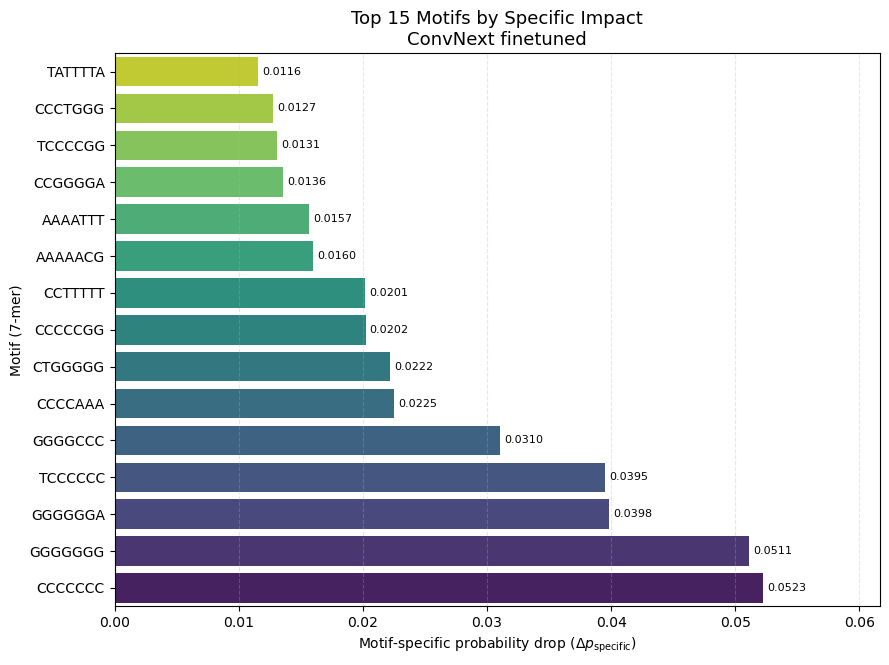

Saved: results_plots/top_motifs_specific_convnext_finetuned.png


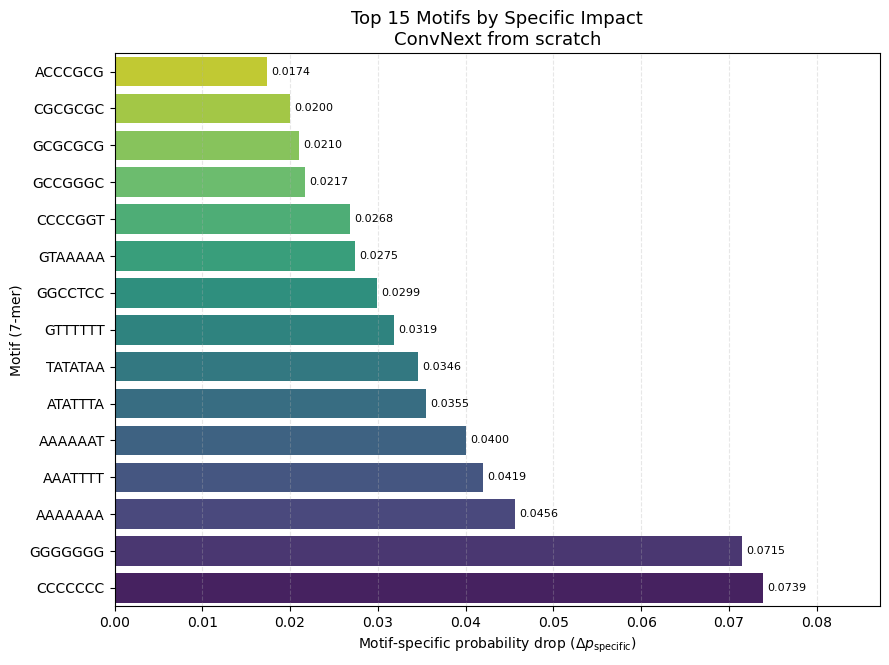

Saved: results_plots/top_motifs_specific_convnext_from_scratch.png


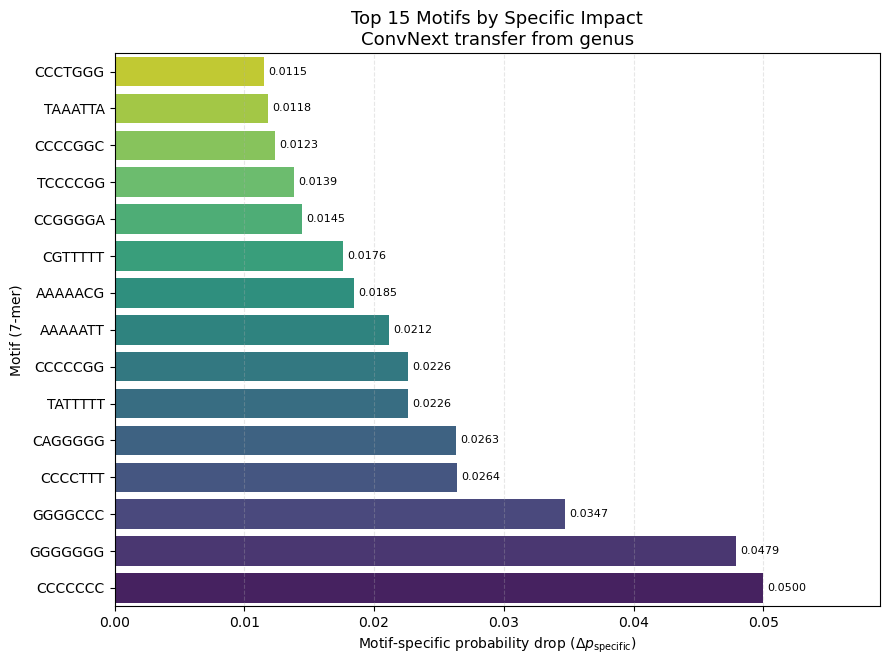

Saved: results_plots/top_motifs_specific_convnext_transfer_from_genus.png


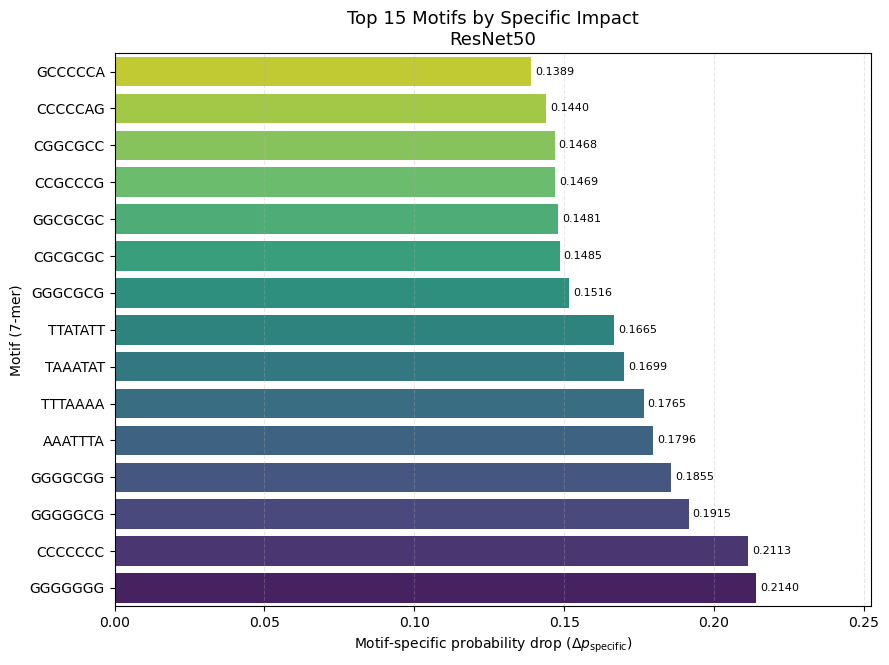

Saved: results_plots/top_motifs_specific_resnet50.png


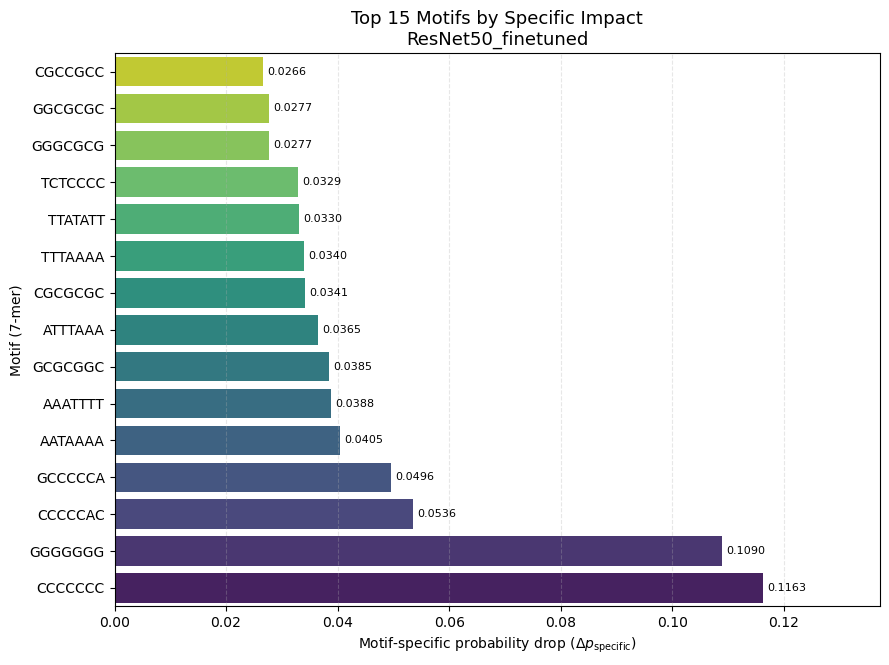

Saved: results_plots/top_motifs_specific_resnet50_finetuned.png


In [17]:
for model_dict in models:
    plot_top_motifs(model_dict['motiffs_rel'])

In [18]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def plot_top_motifs_top1_ratio(
    df,
    ratio_threshold=0.15,
    min_sequences=5
):
    """
    Plot motifs whose motif-specific impact is at least a fraction
    `ratio_threshold` of the strongest validated motif.

    Only motifs satisfying:
      - FDR significance;
      - positive motif-specific effect;
      - minimum number of sequences;
    are considered.
    """

    # =========================================================
    # 1. Filtrar apenas motifs validados
    # =========================================================

    df_valid = df[
        (df["significant_fdr"] == True)
        & (df["mean_specific_drop"] > 0)
        & (df["n_sequences"] >= min_sequences)
    ].copy()

    model_name = (
        str(df["model_name"].iloc[0])
        if "model_name" in df.columns
        else "Model"
    )

    if df_valid.empty:
        print(
            f"No statistically validated motifs found for "
            f"{model_name}."
        )
        return None

    # Evita o problema das categorias residuais do Pandas
    df_valid["motif"] = df_valid["motif"].astype(str)

    # =========================================================
    # 2. Ordenar pelo efeito específico
    # =========================================================

    df_sorted = (
        df_valid
        .sort_values(
            "mean_specific_drop",
            ascending=False
        )
        .reset_index(drop=True)
    )

    impacto_top1 = df_sorted[
        "mean_specific_drop"
    ].iloc[0]

    if impacto_top1 <= 0:
        print(
            f"No positive motif-specific effect found for "
            f"{model_name}."
        )
        return None

    # =========================================================
    # 3. Corte proporcional ao Top 1
    # =========================================================

    valor_limite_corte = (
        impacto_top1 * ratio_threshold
    )

    top_df = df_sorted[
        df_sorted["mean_specific_drop"]
        >= valor_limite_corte
    ].copy()

    if top_df.empty:
        top_df = df_sorted.head(1).copy()

    # remove definitivamente categorias antigas
    top_df["motif"] = (
        top_df["motif"]
        .astype(str)
    )

    qtd_motifs_plotados = len(top_df)

    # Soma somente efeitos positivos e validados
    soma_total_importancia = (
        df_sorted["mean_specific_drop"].sum()
    )

    soma_motifs_exibidos = (
        top_df["mean_specific_drop"].sum()
    )

    coverage = (
        soma_motifs_exibidos
        / soma_total_importancia
        if soma_total_importancia > 0
        else 0
    )

    print(
        f"{model_name}: "
        f"{qtd_motifs_plotados} motifs retained "
        f"(>= {ratio_threshold * 100:.0f}% of Top 1)."
    )

    # =========================================================
    # 4. Ordem explícita das barras
    # =========================================================

    motif_order = top_df["motif"].tolist()

    # =========================================================
    # 5. Plot
    # =========================================================

    altura_grafico = max(
        4.5,
        qtd_motifs_plotados * 0.45
    )

    fig, ax = plt.subplots(
        figsize=(10, altura_grafico)
    )

    sns.barplot(
        data=top_df,
        x="mean_specific_drop",
        y="motif",
        hue="motif",
        order=motif_order,
        palette="viridis",
        legend=False,
        ax=ax
    )

    # Maior efeito no topo
    ax.invert_yaxis()

    # =========================================================
    # 6. Linha do threshold
    # =========================================================

    ax.axvline(
        x=valor_limite_corte,
        linestyle="--",
        alpha=0.6,
        label=(
            f"{ratio_threshold * 100:.0f}% "
            "of Top 1"
        )
    )

    # =========================================================
    # 7. Anotações das barras
    # =========================================================

    for patch, (_, row) in zip(
        ax.patches,
        top_df.iterrows()
    ):

        value = row["mean_specific_drop"]

        proportion = (
            value / impacto_top1
        ) * 100

        ax.text(
            value + impacto_top1 * 0.012,
            patch.get_y() + patch.get_height() / 2,
            f"{proportion:.1f}%",
            va="center",
            fontsize=8.5
        )

    # =========================================================
    # 8. Metadata box
    # =========================================================

    texto_informativo = (
        f"Top-1 effect: {impacto_top1:.4f}\n"
        f"Threshold: {valor_limite_corte:.4f}\n"
        f"Validated motifs: {len(df_sorted)}\n"
        f"Displayed motifs: {qtd_motifs_plotados}\n"
        f"Displayed effect coverage: {coverage * 100:.1f}%"
    )

    ax.text(
        0.98,
        0.03,
        texto_informativo,
        transform=ax.transAxes,
        fontsize=8.5,
        verticalalignment="bottom",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray"
        )
    )

    # =========================================================
    # 9. Labels
    # =========================================================

    ax.set_title(
        "Motifs Retained by Relative Specific-Impact Threshold\n"
        f"{model_name}",
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Motif-specific probability drop "
        r"($\Delta p_{\mathrm{specific}}$)",
        fontweight="bold"
    )

    ax.set_ylabel(
        "Motif (7-mer)",
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_xlim(
        0,
        impacto_top1 * 1.30
    )

    ax.legend(
        loc="upper right",
        frameon=False
    )

    fig.tight_layout()

    # =========================================================
    # 10. Save
    # =========================================================

    os.makedirs(
        "results_plots",
        exist_ok=True
    )

    name_clean = (
        model_name
        .replace(" ", "_")
        .lower()
    )

    path_save = os.path.join(
        "results_plots",
        f"top_motifs_ratio_top1_{name_clean}.png"
    )

    fig.savefig(
        path_save,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        f"Saved: {path_save}"
    )

    plt.show()
    plt.close(fig)

    return top_df

ConvNext finetuned: 5 motifs retained (>= 50% of Top 1).
Saved: results_plots/top_motifs_ratio_top1_convnext_finetuned.png


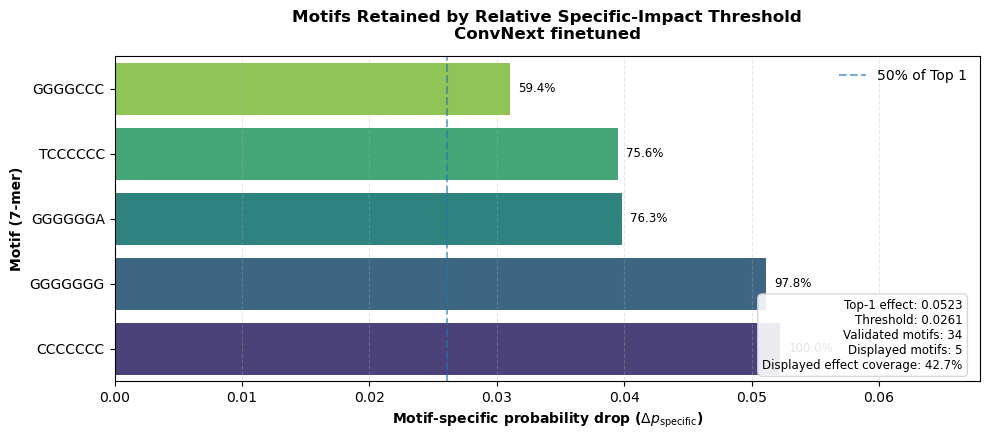

ConvNext from scratch: 5 motifs retained (>= 50% of Top 1).
Saved: results_plots/top_motifs_ratio_top1_convnext_from_scratch.png


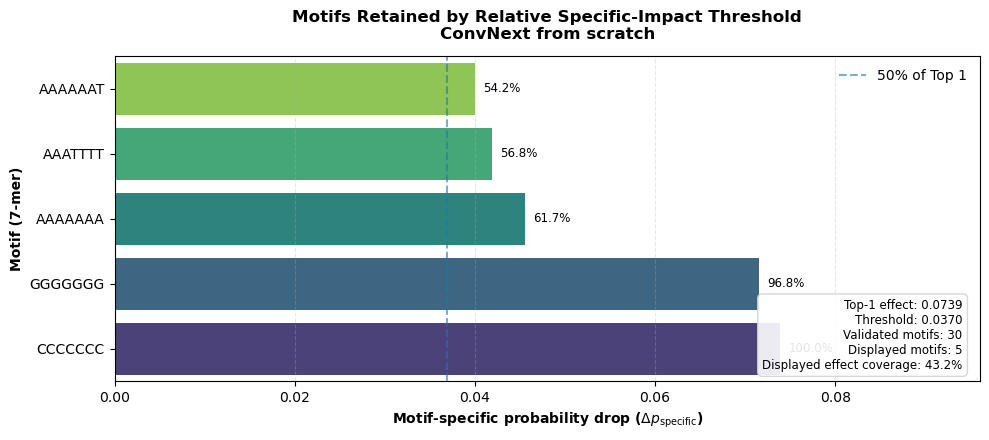

ConvNext transfer from genus: 5 motifs retained (>= 50% of Top 1).
Saved: results_plots/top_motifs_ratio_top1_convnext_transfer_from_genus.png


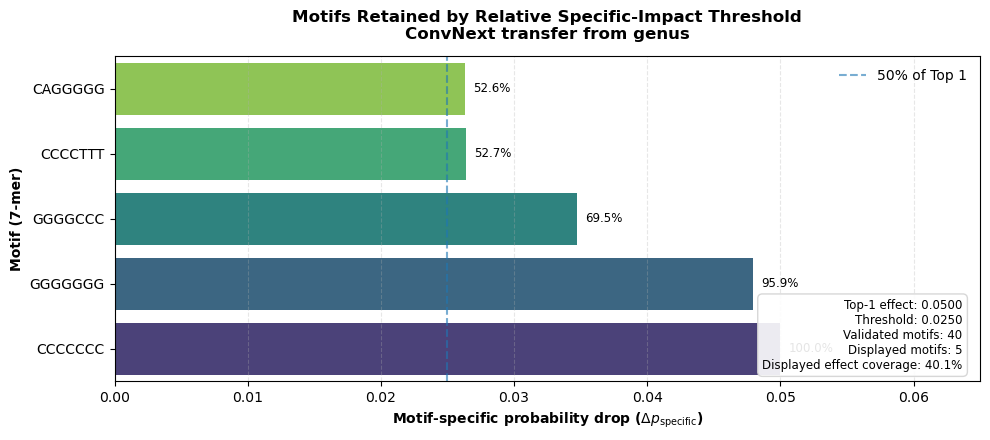

ResNet50: 20 motifs retained (>= 50% of Top 1).
Saved: results_plots/top_motifs_ratio_top1_resnet50.png


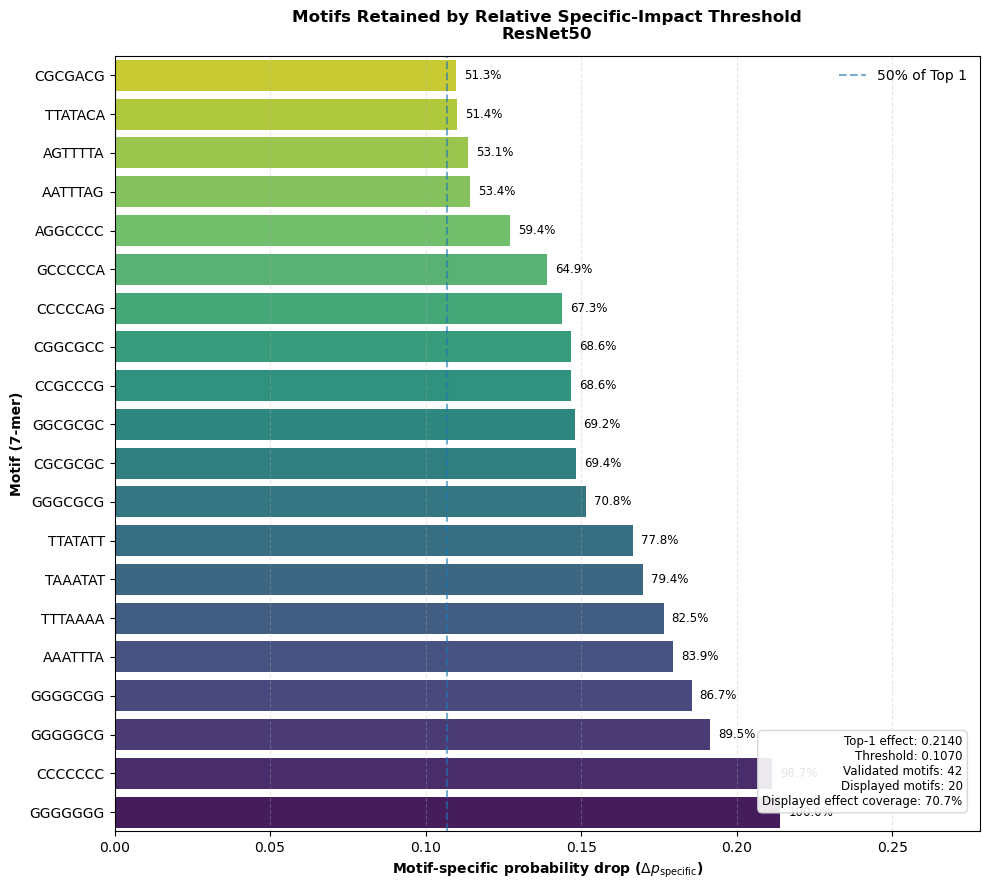

ResNet50_finetuned: 2 motifs retained (>= 50% of Top 1).
Saved: results_plots/top_motifs_ratio_top1_resnet50_finetuned.png


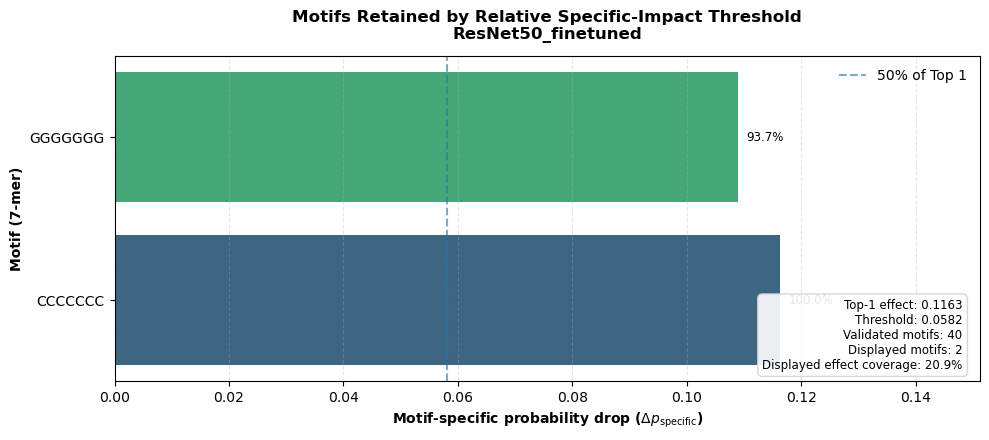

In [19]:
for model_dict in models:
    plot_top_motifs_top1_ratio(model_dict['motiffs_rel'],ratio_threshold=0.50)

In [20]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def plot_top_motifs_compact_view(
    df,
    target_coverage=0.75,
    max_bars=20,
    min_sequences=5
):
    """
    Compact view of statistically validated motifs based on cumulative
    motif-specific impact coverage.

    Only motifs satisfying:
      - FDR significance;
      - positive motif-specific effect;
      - minimum number of sequences;
    are considered.
    """

    # =========================================================
    # 1. Model name
    # =========================================================

    model_name = (
        str(df["model_name"].iloc[0])
        if "model_name" in df.columns
        else "Model"
    )

    # =========================================================
    # 2. Keep only validated positive motifs
    # =========================================================

    df_valid = df[
        (df["significant_fdr"] == True)
        & (df["mean_specific_drop"] > 0)
        & (df["n_sequences"] >= min_sequences)
    ].copy()

    if df_valid.empty:
        print(
            f"No statistically validated motifs found for "
            f"{model_name}."
        )
        return None

    # Remove unused categorical levels
    df_valid["motif"] = df_valid["motif"].astype(str)

    # =========================================================
    # 3. Sort by motif-specific effect
    # =========================================================

    df_sorted = (
        df_valid
        .sort_values(
            "mean_specific_drop",
            ascending=False
        )
        .reset_index(drop=True)
    )

    total_specific_effect = (
        df_sorted["mean_specific_drop"].sum()
    )

    if total_specific_effect <= 0:
        print(
            f"No positive cumulative motif-specific effect "
            f"for {model_name}."
        )
        return None

    # =========================================================
    # 4. Relative and cumulative contribution
    # =========================================================

    df_sorted["relative_specific_effect"] = (
        df_sorted["mean_specific_drop"]
        / total_specific_effect
    )

    df_sorted["cumulative_specific_effect"] = (
        df_sorted["relative_specific_effect"]
        .cumsum()
    )

    # =========================================================
    # 5. Retain motifs until target coverage is reached
    #
    # shift() ensures the motif that crosses the threshold
    # is also included.
    # =========================================================

    keep_mask = (
        df_sorted["cumulative_specific_effect"]
        .shift(1, fill_value=0)
        < target_coverage
    )

    df_filtered = df_sorted[
        keep_mask
    ].copy()

    # =========================================================
    # 6. Optional visualization limit
    # =========================================================

    if len(df_filtered) > max_bars:

        top_df = (
            df_filtered
            .head(max_bars)
            .copy()
        )

        note = (
            f"Visualization limited to "
            f"{max_bars} motifs"
        )

    else:

        top_df = df_filtered.copy()

        note = (
            f"Target coverage: "
            f"{target_coverage * 100:.0f}%"
        )

    if top_df.empty:
        return None

    top_df["motif"] = (
        top_df["motif"]
        .astype(str)
    )

    n_displayed = len(top_df)

    actual_coverage = (
        top_df["mean_specific_drop"].sum()
        / total_specific_effect
    )

    print(
        f"{model_name}: "
        f"{n_displayed} motifs displayed | "
        f"coverage = {actual_coverage * 100:.1f}%"
    )

    # =========================================================
    # 7. Explicit motif order
    # =========================================================

    motif_order = (
        top_df["motif"]
        .tolist()
    )

    # =========================================================
    # 8. Plot
    # =========================================================

    figure_height = max(
        4.5,
        n_displayed * 0.42
    )

    fig, ax = plt.subplots(
        figsize=(10, figure_height)
    )

    sns.barplot(
        data=top_df,
        x="mean_specific_drop",
        y="motif",
        hue="motif",
        order=motif_order,
        palette="viridis",
        legend=False,
        ax=ax
    )

    # Highest impact at the top
    ax.invert_yaxis()

    # =========================================================
    # 9. Annotate cumulative contribution
    # =========================================================

    max_effect = (
        top_df["mean_specific_drop"]
        .max()
    )

    for patch, (_, row) in zip(
        ax.patches,
        top_df.iterrows()
    ):

        cumulative_pct = (
            row["cumulative_specific_effect"]
            * 100
        )

        value = row[
            "mean_specific_drop"
        ]

        ax.text(
            value + max_effect * 0.012,
            patch.get_y()
            + patch.get_height() / 2,
            f"{cumulative_pct:.1f}%",
            va="center",
            fontsize=8.5
        )

    # =========================================================
    # 10. Information box
    # =========================================================

    info_text = (
        f"Validated motifs: {len(df_sorted)}\n"
        f"Displayed motifs: {n_displayed}\n"
        f"Displayed coverage: "
        f"{actual_coverage * 100:.1f}%\n"
        f"{note}"
    )

    ax.text(
        0.98,
        0.03,
        info_text,
        transform=ax.transAxes,
        fontsize=8.5,
        verticalalignment="bottom",
        horizontalalignment="right",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray"
        )
    )

    # =========================================================
    # 11. Labels
    # =========================================================

    ax.set_title(
        "Compact Motif-Specific Signature\n"
        f"{model_name}",
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Motif-specific probability drop "
        r"($\Delta p_{\mathrm{specific}}$)",
        fontweight="bold"
    )

    ax.set_ylabel(
        "Motif (7-mer)",
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )

    ax.set_xlim(
        0,
        max_effect * 1.22
    )

    fig.tight_layout()

    # =========================================================
    # 12. Save
    # =========================================================

    os.makedirs(
        "results_plots",
        exist_ok=True
    )

    clean_name = (
        model_name
        .replace(" ", "_")
        .lower()
    )

    output_path = (
        f"results_plots/"
        f"top_motifs_compact_{clean_name}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        f"Saved: {output_path}"
    )

    plt.show()
    plt.close(fig)

    return top_df

ConvNext finetuned: 15 motifs displayed | coverage = 76.1%
Saved: results_plots/top_motifs_compact_convnext_finetuned.png


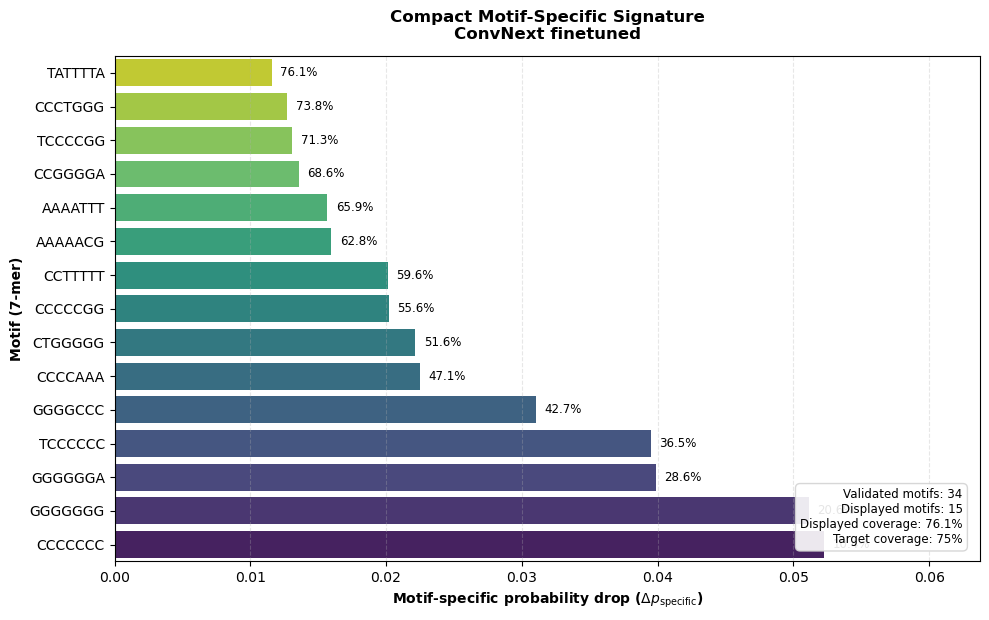

ConvNext from scratch: 12 motifs displayed | coverage = 76.1%
Saved: results_plots/top_motifs_compact_convnext_from_scratch.png


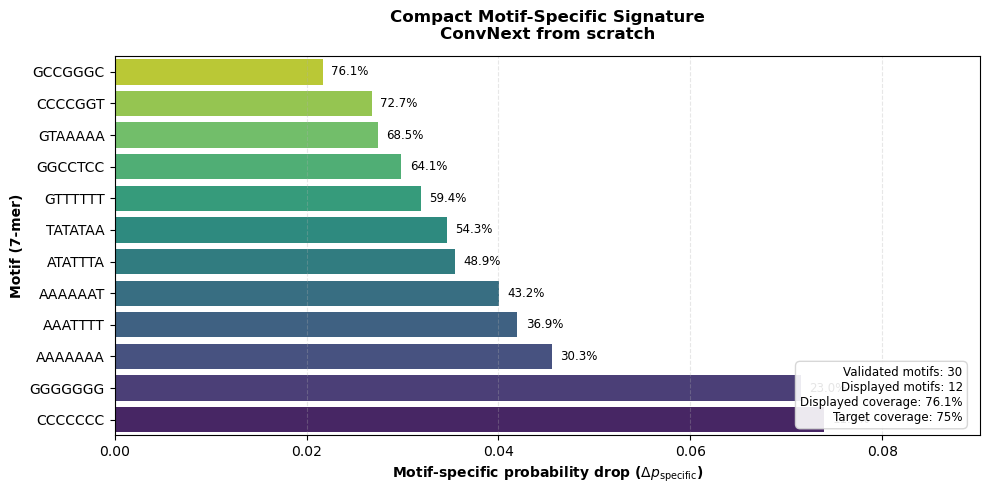

ConvNext transfer from genus: 15 motifs displayed | coverage = 76.1%
Saved: results_plots/top_motifs_compact_convnext_transfer_from_genus.png


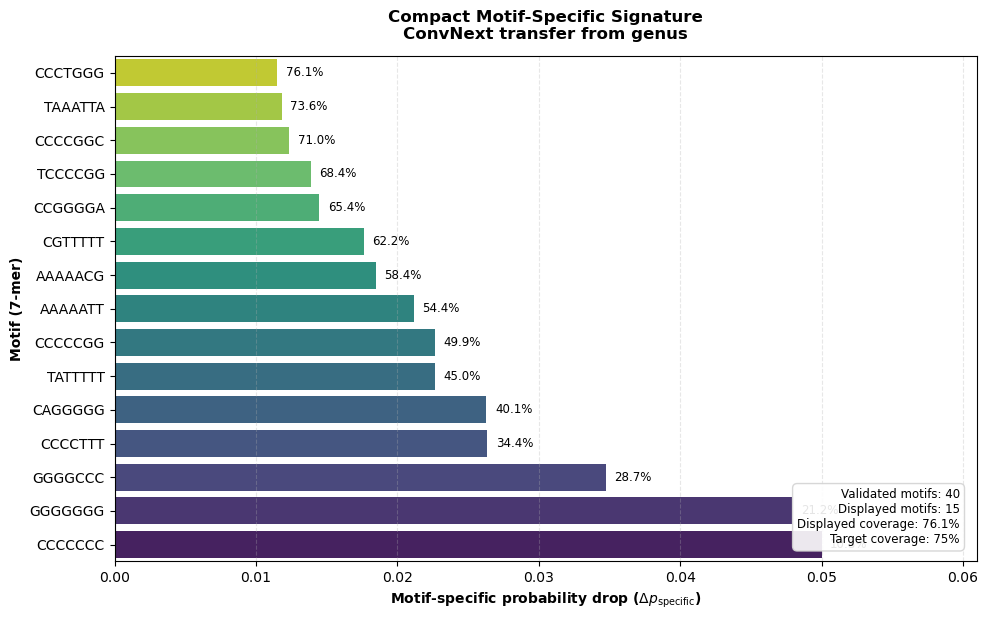

ResNet50: 20 motifs displayed | coverage = 70.7%
Saved: results_plots/top_motifs_compact_resnet50.png


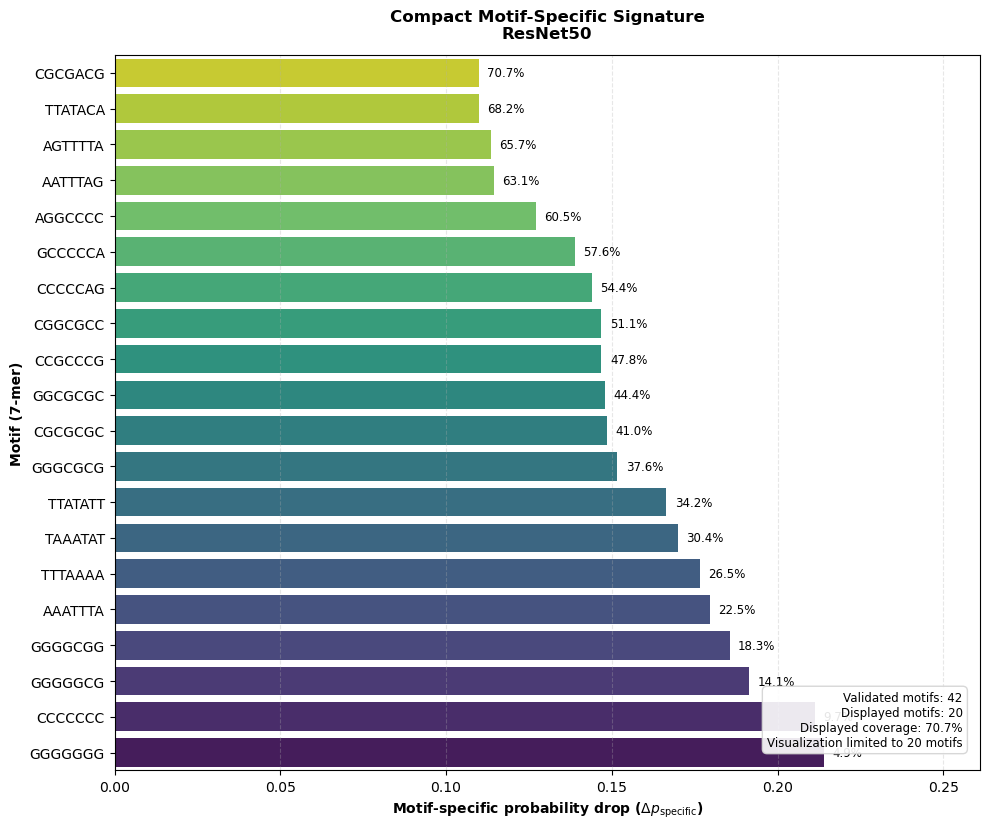

ResNet50_finetuned: 20 motifs displayed | coverage = 75.5%
Saved: results_plots/top_motifs_compact_resnet50_finetuned.png


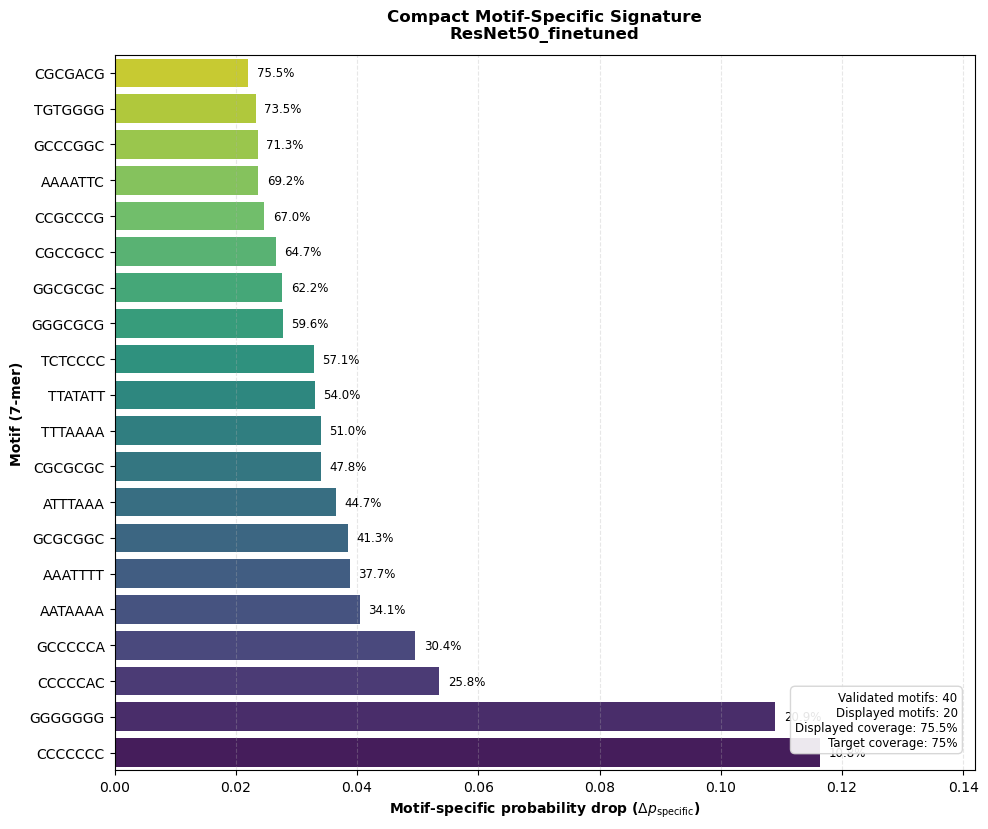

In [21]:
for model_dict in models:
    plot_top_motifs_compact_view(model_dict['motiffs_rel'])

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

def generate_slope_graph(df_list, model_names, title, top_n=10, min_label_dist=0.0002):
    """
    Gera um Slope Graph com ajuste automático de labels para evitar sobreposição.
    min_label_dist: Distância vertical mínima entre labels (ajuste conforme a escala do seu impacto).
    """
    plt.figure(figsize=(14, 10))
    
    # 1. Identificar motifs no Top N de qualquer um dos modelos
    all_top_motifs = set()
    for df in df_list:
        all_top_motifs.update(df.sort_values('mean_specific_drop', ascending=False).head(top_n)['motif'])
    
    all_top_motifs = sorted(list(all_top_motifs))
    x_coords = np.arange(len(model_names))
    motif_data = []

    # 2. Coletar dados e plotar as linhas principais
    for motif in all_top_motifs:
        impacts = []
        for df in df_list:
            val = df[df['motif'] == motif]['mean_specific_drop'].values
            impacts.append(val[0] if len(val) > 0 else np.nan)
        motif_data.append({'motif': motif, 'impacts': impacts})
        plt.plot(x_coords, impacts, marker='o', linewidth=2.5, alpha=0.6)

    # Função interna para calcular posições não sobrepostas
    def get_adjusted_y(original_y, min_dist):
        if len(original_y) == 0: return []
        idx = np.argsort(original_y)
        y_sorted = np.array(original_y)[idx]
        for i in range(1, len(y_sorted)):
            if y_sorted[i] - y_sorted[i-1] < min_dist:
                y_sorted[i] = y_sorted[i-1] + min_dist
        new_y = np.zeros_like(y_sorted)
        new_y[idx] = y_sorted
        return new_y

    # 3. Plotagem das Labels (Esquerda e Direita)
    for side_idx, side_label in zip([0, -1], ['left', 'right']):
        original_y = [d['impacts'][side_idx] for d in motif_data]
        adj_y = get_adjusted_y(original_y, min_label_dist)
        
        ha = 'right' if side_idx == 0 else 'left'
        offset = -0.08 if side_idx == 0 else 0.08
        
        for i, d in enumerate(motif_data):
            # Desenha o texto na posição ajustada
            plt.text(x_coords[side_idx] + offset, adj_y[i], d['motif'], 
                     ha=ha, va='center', fontsize=10, fontweight='bold')
            
            # Desenha linha conetora pontilhada se houve ajuste significativo
            if abs(adj_y[i] - original_y[i]) > 1e-7:
                plt.plot([x_coords[side_idx] + (offset*0.8), x_coords[side_idx]], 
                         [adj_y[i], original_y[i]], color='gray', linestyle=':', linewidth=0.8, alpha=0.5)

    # 4. Estética Final (Padrão Dissertação)
    plt.xticks(x_coords, model_names, fontsize=13, fontweight='bold')
    plt.title(title, fontsize=16, pad=30, fontweight='bold')
    plt.ylabel('Impacto (Queda na Probabilidade)', fontsize=13)
    
    # Remove moldura para um visual mais limpo
    for spine in plt.gca().spines.values():
        spine.set_visible(False)
        
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Exemplo de Uso ---
# generate_improved_slope_graph([df_scratch, df_transfer, df_fine], 
#                               ['Scratch', 'Transfer Genus', 'Finetuned'],
#                               'Evolução da Importância de Motifs - ConvNext',
#                               min_label_dist=0.0003)

In [26]:
results_convnext = []
names_convnext = []

results_resnet = []
names_resnet = []

for model_dict in models:
    if model_dict['model_name'].lower().startswith("convnext"):
        names_convnext.append(model_dict['model_name'])
        results_convnext.append(model_dict['motiffs_rel'])
    elif model_dict['model_name'].lower().startswith("resnet"):
        names_resnet.append(model_dict['model_name'])
        results_resnet.append(model_dict['motiffs_rel'])

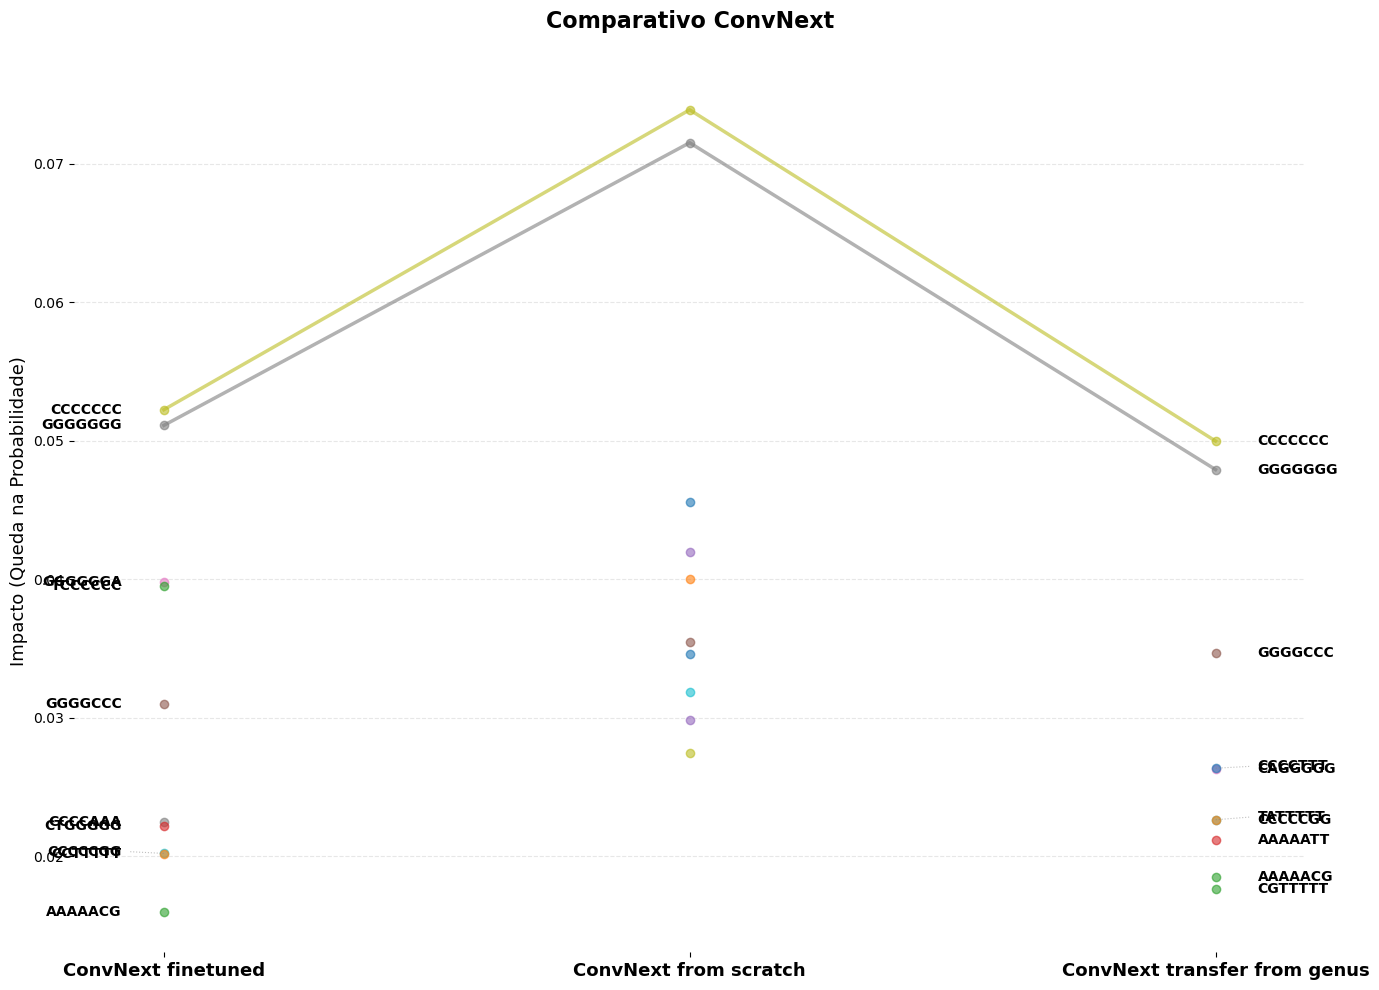

In [27]:
generate_slope_graph(results_convnext, 
                     names_convnext,
                     'Comparativo ConvNext')

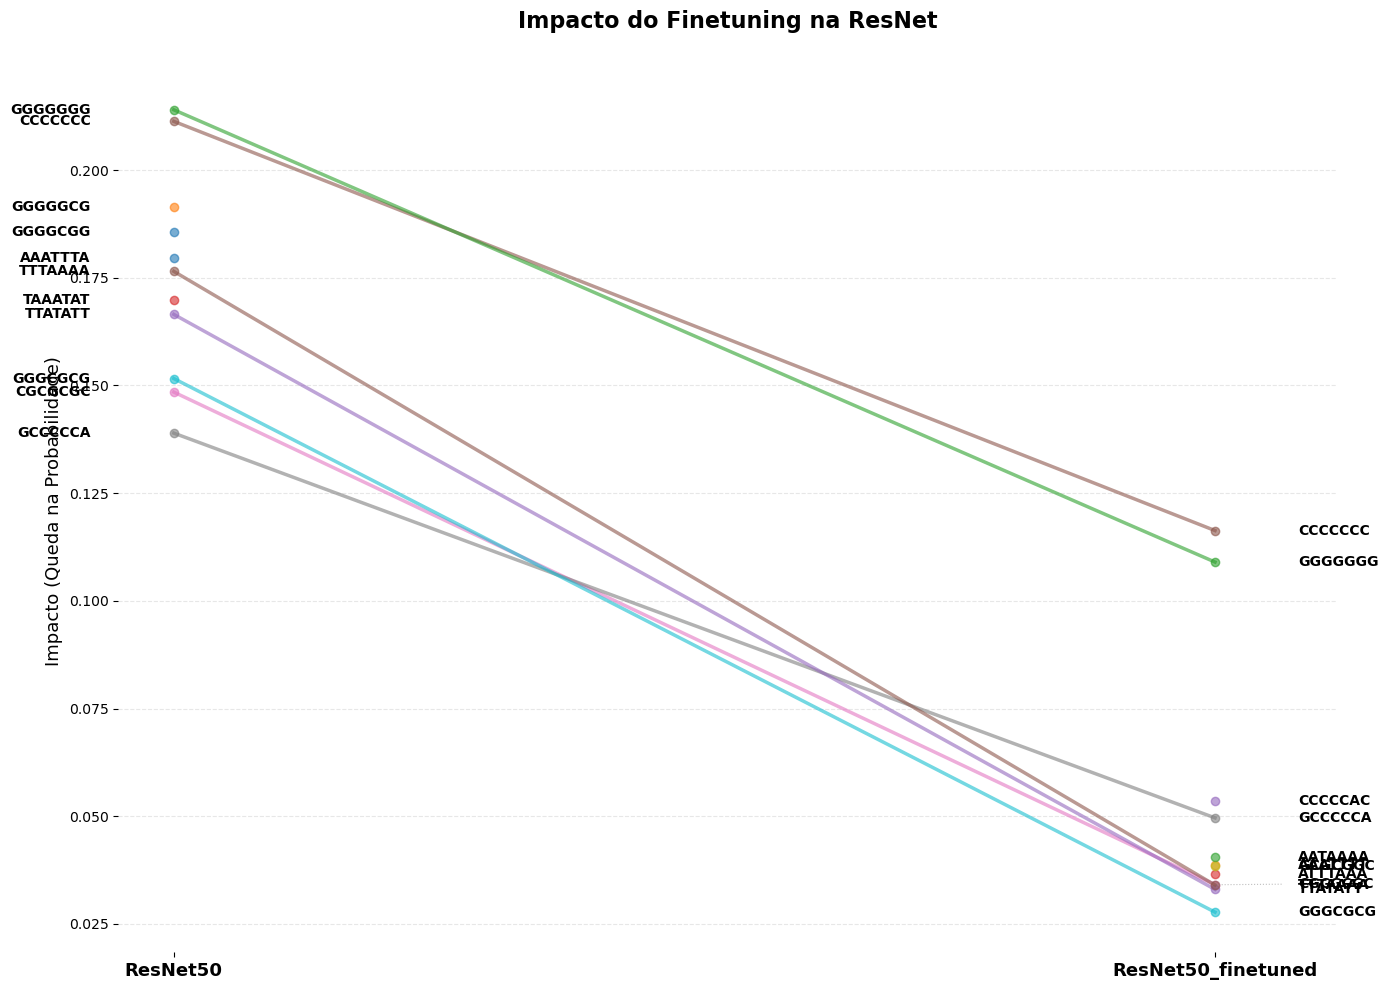

In [28]:
generate_slope_graph(results_resnet, 
                     names_resnet,
                     'Impacto do Finetuning na ResNet')

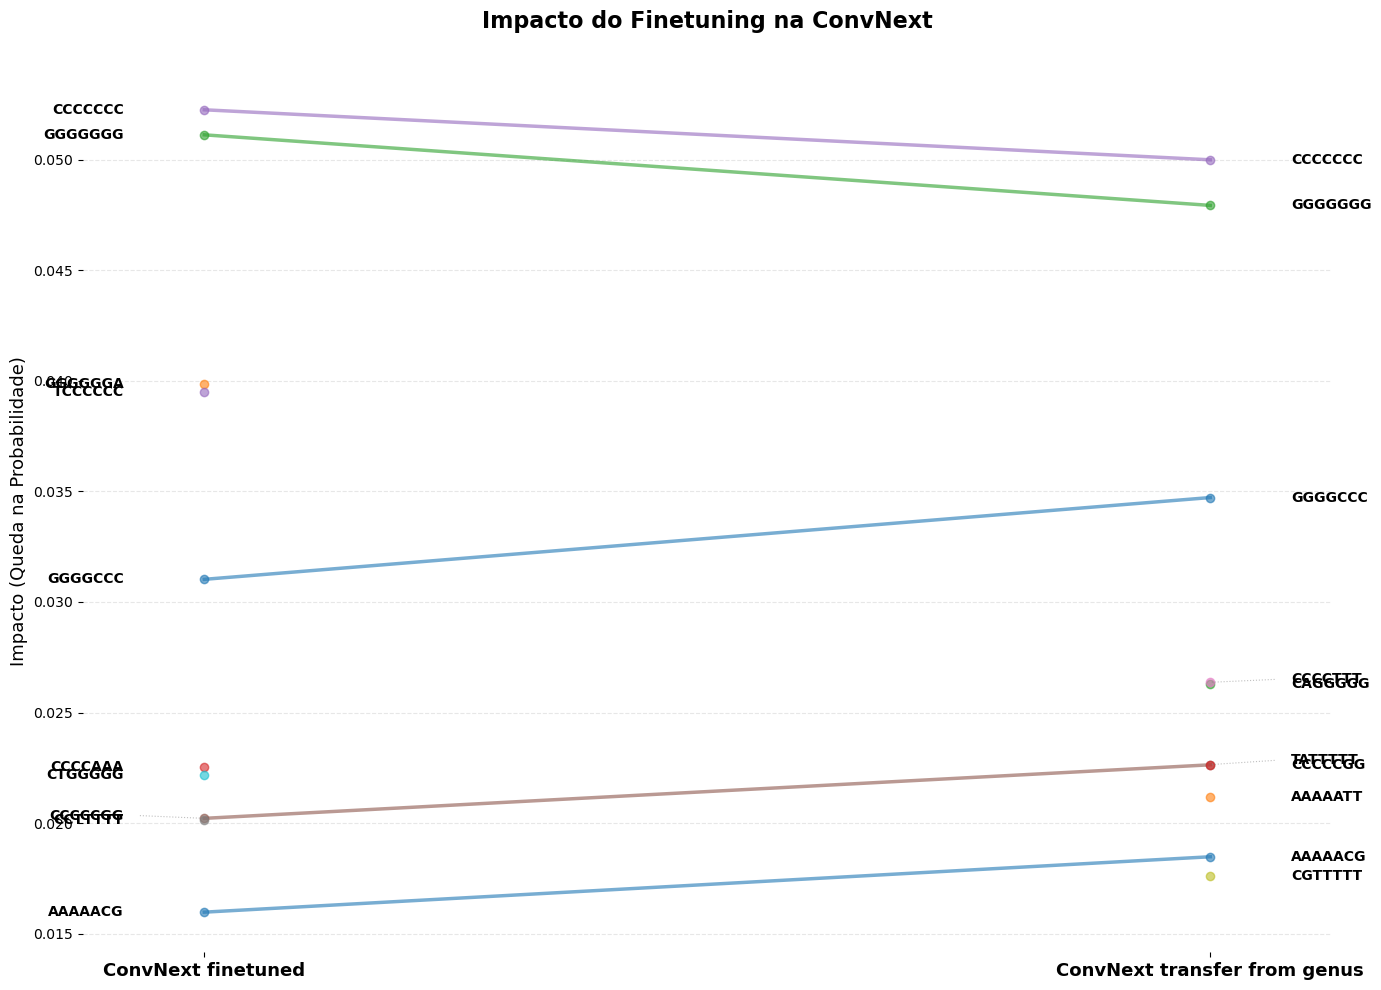

In [29]:
generate_slope_graph([results_convnext[0],results_convnext[2]], 
                     [names_convnext[0],names_convnext[2]],
                     'Impacto do Finetuning na ConvNext')

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Função para calcular Conteúdo GC (%)
def calculate_gc(seq):
    return (seq.count('G') + seq.count('C')) / len(seq) * 100

# 2. Categorização (Binning)
def bin_gc(gc):
    if gc <= 30: return 'Low GC (0-30%)'
    if gc <= 60: return 'Med GC (30-60%)'
    return 'High GC (60-100%)'

def generate_gc_graph(df):
    df = get_validated_motifs(df).copy()
    
    model_name = str(
        df["model_name"].iloc[0]
    )
    
    # 3. Processamento
    df['gc_content'] = df['motif'].apply(calculate_gc)
    df['gc_range'] = df['gc_content'].apply(bin_gc)

    # 4. Plotagem
    plt.figure(figsize=(10, 7))
    sns.violinplot(data=df, x='gc_range', y='mean_specific_drop', 
                   palette='muted', inner='point',
                   order=['Low GC (0-30%)', 'Med GC (30-60%)', 'High GC (60-100%)'])
    
    plt.title(f'Distribuição do Impacto por Conteúdo GC - {model_name}')
    plt.xlabel('GC (%)')
    plt.ylabel('Impact')
    plt.savefig(f'violin_impact_vs_gc{model_name}.png')

/tmp/ipykernel_59971/1873513268.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_specific_drop',
/tmp/ipykernel_59971/1873513268.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_specific_drop',
/tmp/ipykernel_59971/1873513268.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='gc_range', y='mean_specific_drop',
/tmp/ipykernel_59971/1873513268.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0

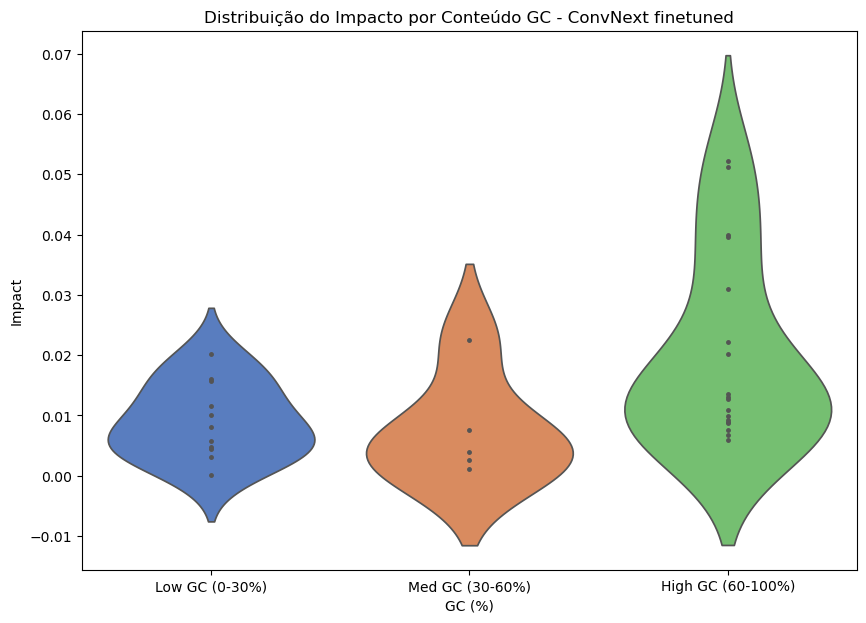

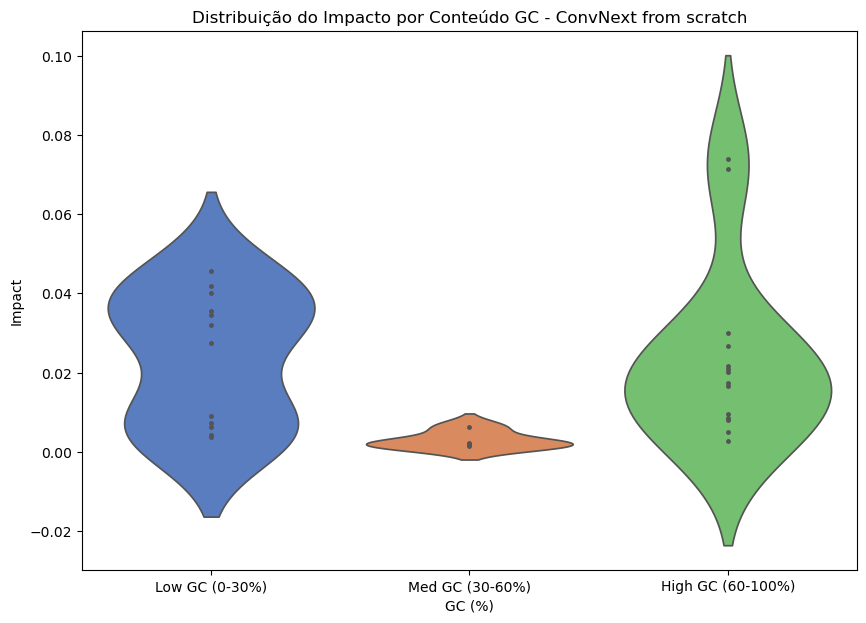

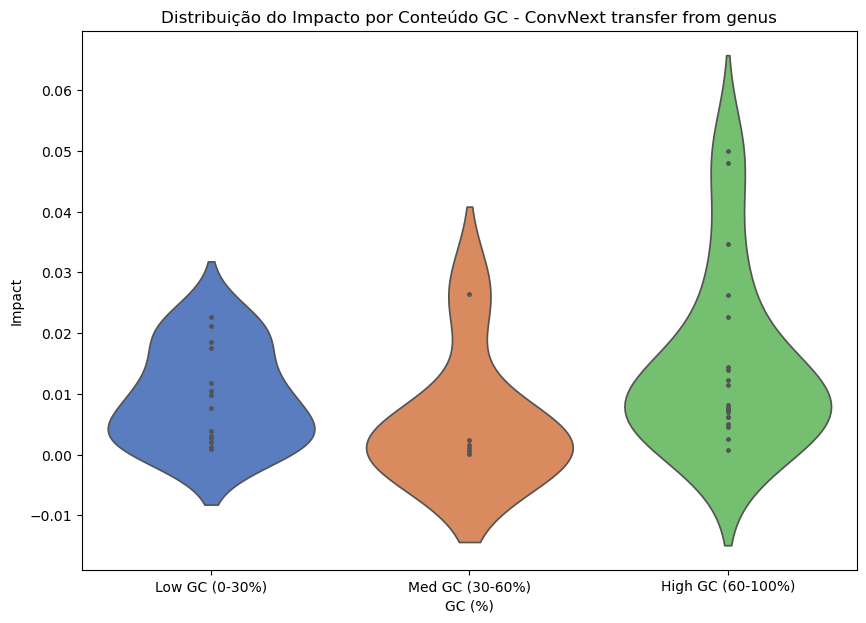

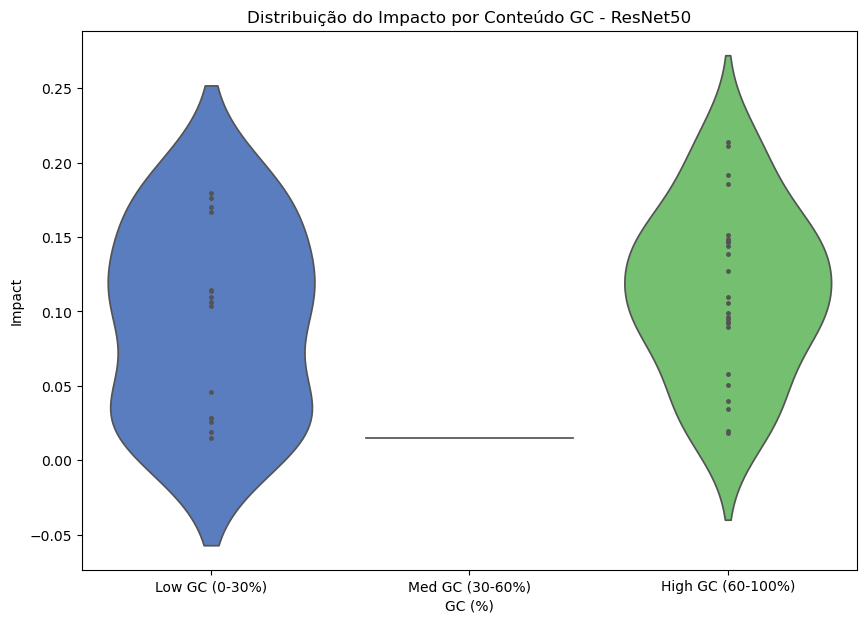

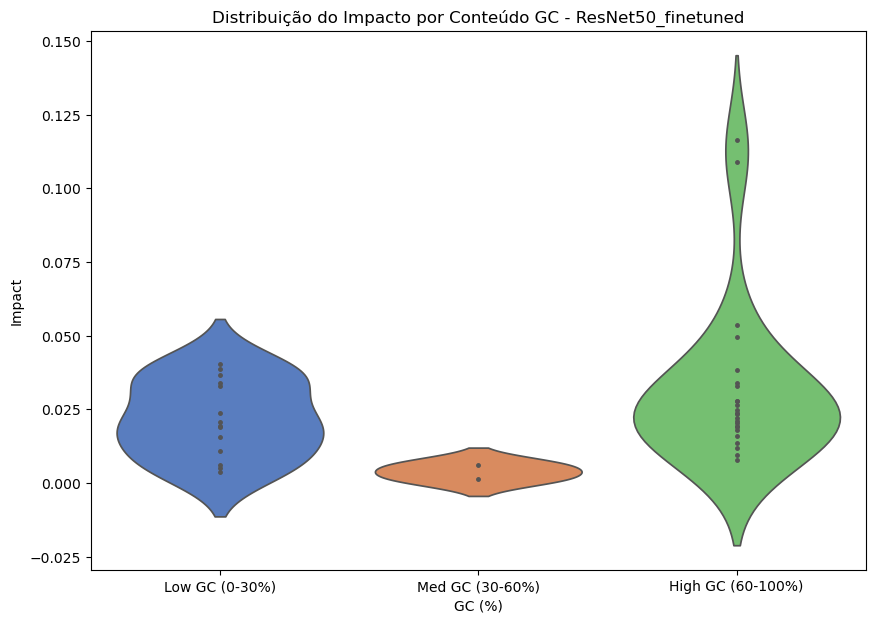

In [35]:
for model_dict in models:
    generate_gc_graph(model_dict['motiffs_rel'])

In [36]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from tqdm import tqdm

def fast_motif_cooccurrence(test_loader, motifs_list, device='cuda'):
    """
    Busca rápida de co-ocorrência usando Conv1D na GPU.
    """
    num_motifs = len(motifs_list)
    K = len(motifs_list[0])
    
    # 1. Preparação dos Filtros (Motifs)
    # Criamos pesos fixos para a convolução: (Num_Motifs, 4, K)
    motif_kernels = torch.zeros((num_motifs, 4, K), device=device)
    base_to_idx = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    for i, m in enumerate(motifs_list):
        for pos, base in enumerate(m):
            if base in base_to_idx:
                motif_kernels[i, base_to_idx[base], pos] = 1.0

    # Inicializa contadores (na GPU para evitar transferências lentas)
    interaction_matrix = torch.zeros((num_motifs, num_motifs), device=device)
    occurrence_counts = torch.zeros(num_motifs, device=device)
    total_sequences = 0

    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Escaneando Genomas"):
            inputs, _ = batch
            if inputs.dim() == 3 and inputs.shape[0] == 1: inputs = inputs.squeeze(0)
            inputs = inputs.to(device).long()
            total_sequences += inputs.shape[0]

            # 2. One-Hot Encoding (Trata '_' mapeando para zeros)
            # search_oh: (Batch, L, 4)
            search_oh = torch.zeros((*inputs.shape, 4), device=device)
            valid_mask = (inputs >= 0) & (inputs < 4)
            if valid_mask.any():
                search_oh[valid_mask] = F.one_hot(inputs[valid_mask], num_classes=4).float()
            
            # Ajusta para Conv1D: (Batch, 4, L)
            search_oh = search_oh.permute(0, 2, 1)
            
            # 3. Busca via Convolução (A mágica da velocidade)
            # Cada match perfeito resultará no valor K (7.0)
            search_results = F.conv1d(search_oh, motif_kernels)
            
            # Verifica se o motif apareceu PELO MENOS UMA VEZ na sequência
            # presence shape: (Batch, Num_Motifs)
            presence = (search_results == K).any(dim=-1).float()
            
            # 4. Atualiza Matrizes (Álgebra linear pura)
            # Multiplicação de matrizes calcula todas as combinações par a par instantaneamente
            interaction_matrix += torch.matmul(presence.T, presence)
            occurrence_counts += presence.sum(dim=0)

    # 5. Normalização (Índice de Jaccard)
    # J = Intersecção / (Contagem_A + Contagem_B - Intersecção)
    counts_i = occurrence_counts.view(-1, 1)
    counts_j = occurrence_counts.view(1, -1)
    union_matrix = counts_i + counts_j - interaction_matrix
    jaccard_matrix = interaction_matrix / torch.clamp(union_matrix, min=1.0)
    
    return jaccard_matrix.cpu().numpy(), motifs_list

In [37]:
for model_dict in models:
    print(f"rodando para: {model_dict['model_name']}")
    validated = get_validated_motifs(
        model_dict["motiffs_rel"]
    )
    
    motifs = validated["motif"].tolist()
    
    model_dict["jaccard_matrix"] = (
        fast_motif_cooccurrence(
            test_loader,
            motifs
        )
    )

rodando para: ConvNext finetuned


Escaneando Genomas: 256it [01:35,  2.68it/s]                         


rodando para: ConvNext from scratch


Escaneando Genomas: 256it [01:34,  2.72it/s]                         


rodando para: ConvNext transfer from genus


Escaneando Genomas: 256it [01:33,  2.73it/s]                         


rodando para: ResNet50


Escaneando Genomas: 256it [01:35,  2.67it/s]                         


rodando para: ResNet50_finetuned


Escaneando Genomas: 256it [01:34,  2.72it/s]                         


In [38]:
for model_dict in models:
    nomes = model_dict['jaccard_matrix'][1]
    df_jaccard = pd.DataFrame(model_dict['jaccard_matrix'][0], index=nomes, columns=nomes)
    df_jaccard.to_parquet(f'results_motifs/motif_interaction_jaccard_{model_dict['model_name'].lower().replace(" ","_")}.parquet')

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage

def plot_motif_clustermap(jaccard_matrix, motif_names, model_name, output_name="clustermap.png"):
    # 1. Preparar o DataFrame
    df = pd.DataFrame(jaccard_matrix, index=motif_names, columns=motif_names)
    
    # 2. Configurar o estilo "Paper"
    sns.set_theme(style="white")
    
    # 3. Gerar o Clustermap
    # cmap: 'mako', 'rocket' ou 'YlGnBu' são ótimas para bioinformática
    distance = 1.0 - jaccard_matrix
    
    np.fill_diagonal(
        distance,
        0
    )
    
    condensed = squareform(
        distance,
        checks=False
    )
    
    Z = linkage(
        condensed,
        method="average"
    )
    
    g = sns.clustermap(
        df,
        row_linkage=Z,
        col_linkage=Z,
        cmap="magma",
        norm=LogNorm(
            vmin=0.001,
            vmax=1
        )
    )
    
    # Ajustar títulos e labels
    g.fig.suptitle(f'Módulos de Motifs: Interação via Índice de Jaccard\nModelo: {model_name}', 
                   fontsize=16, fontweight='bold', y=1.02)
    
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
    
    # 4. Salvar
    plt.savefig(output_name, dpi=300, bbox_inches='tight')
    plt.show()

# --- Exemplo de Uso ---
# plot_motif_clustermap(matriz_jaccard, nomes, "ConvNext finetuned")

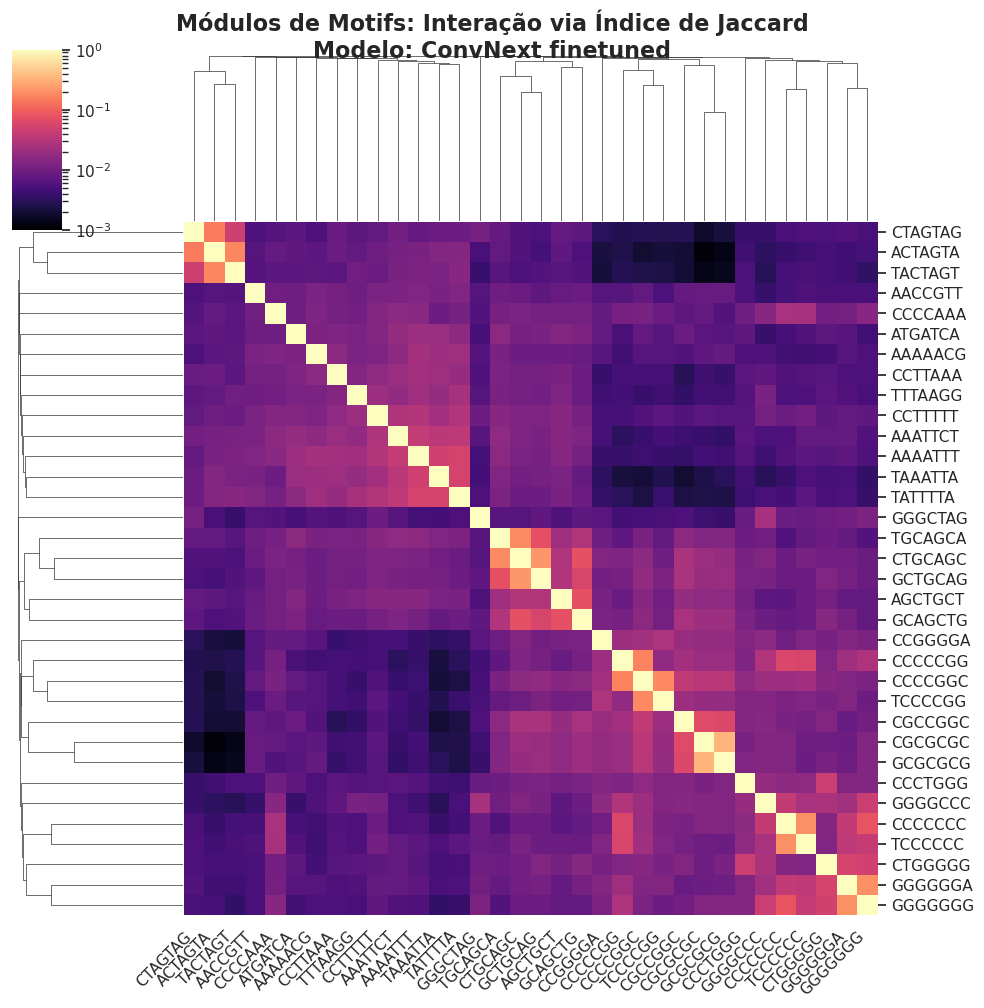

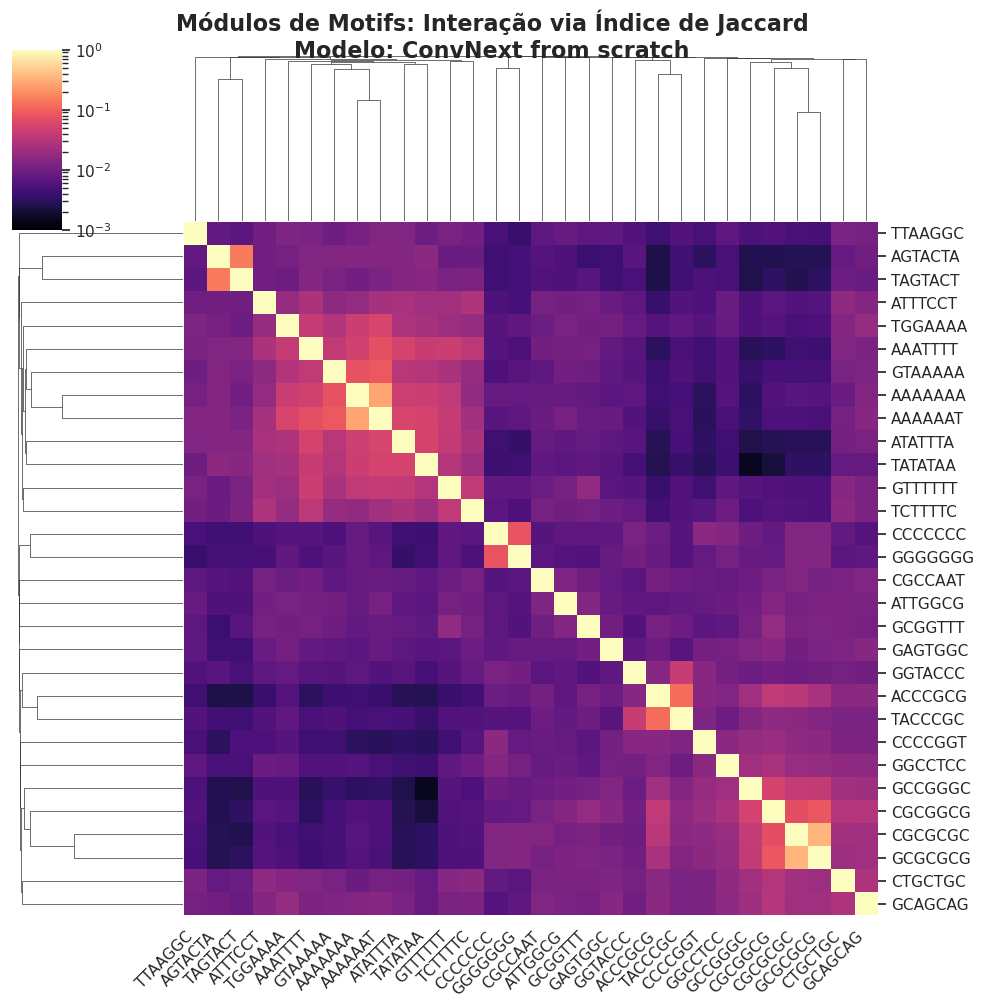

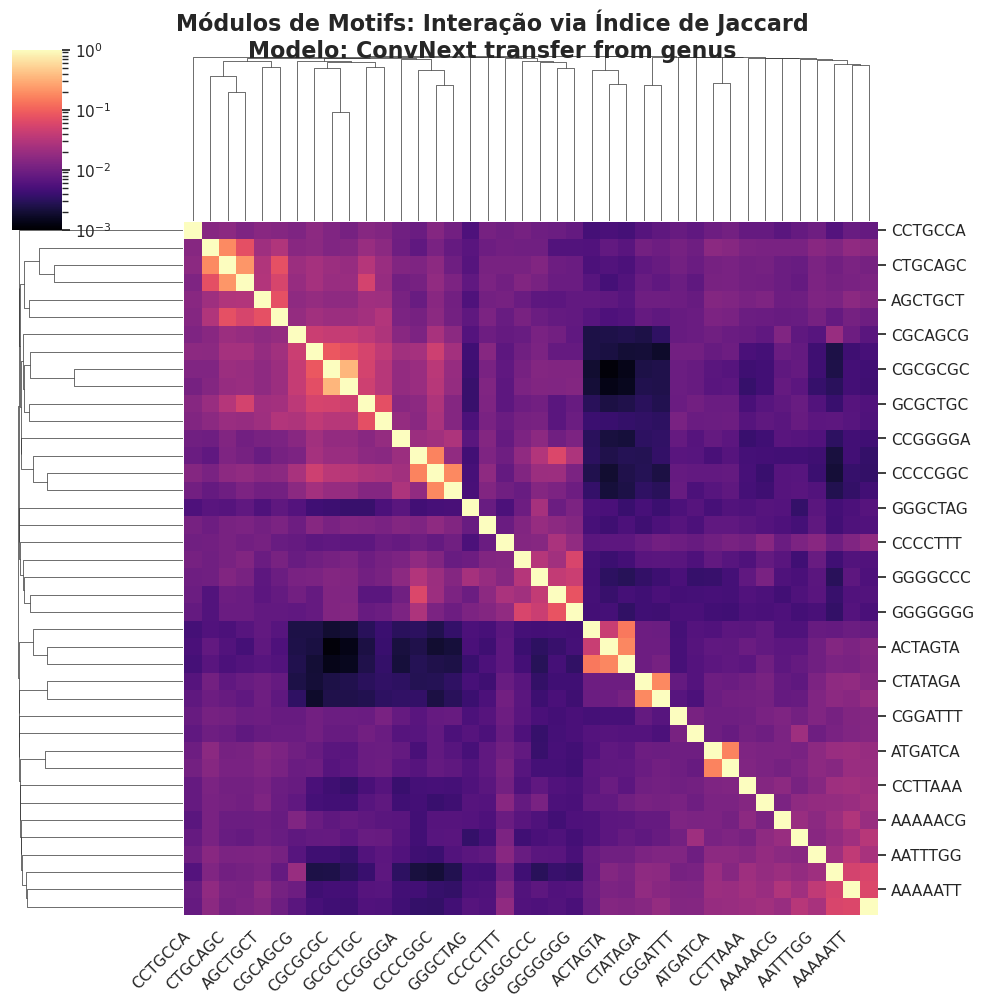

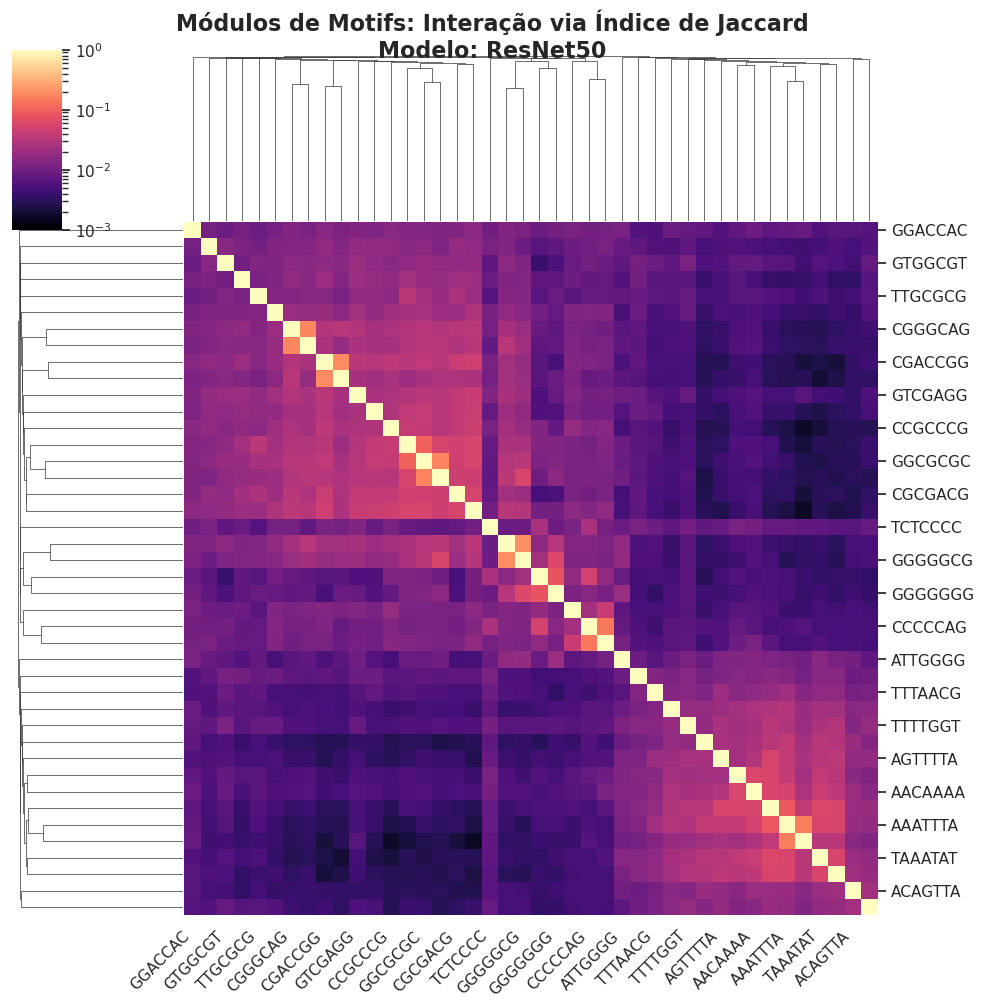

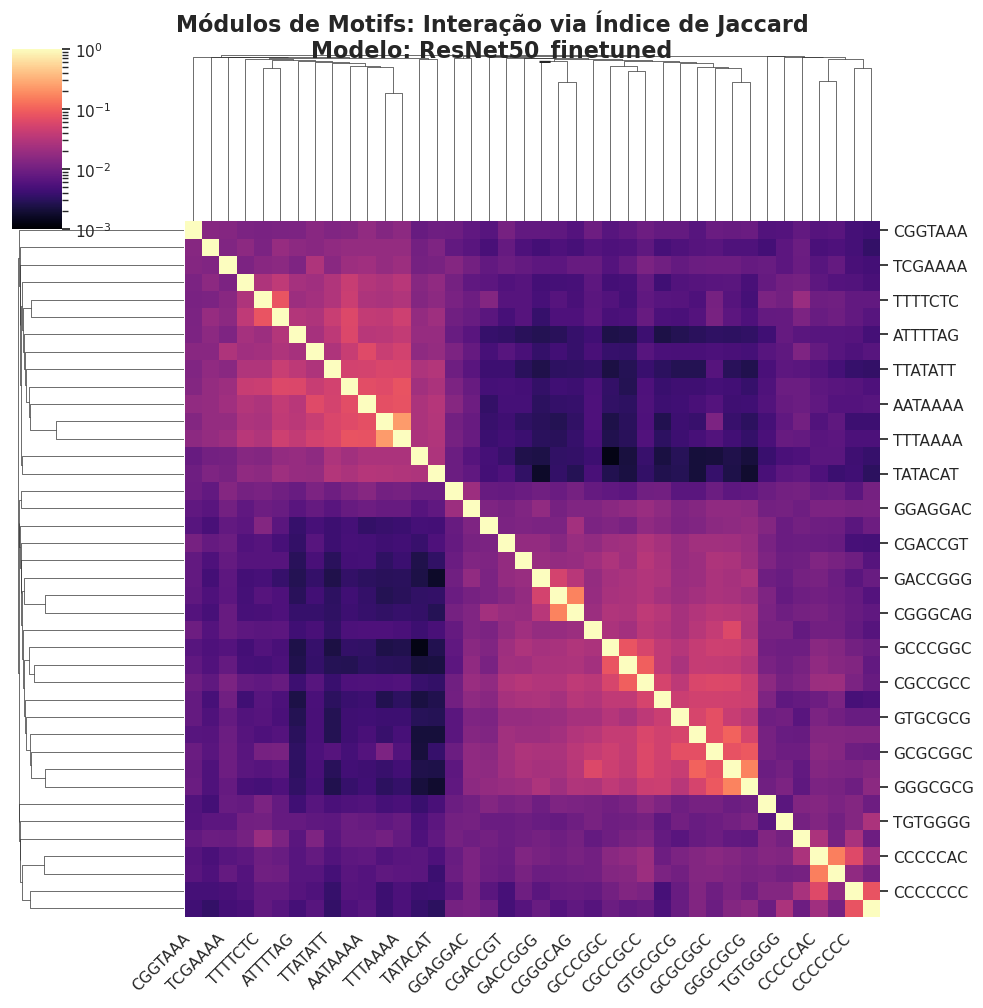

In [40]:
for model_dict in models:
    motif_names = model_dict['jaccard_matrix'][1]
    jaccard_matrix = model_dict['jaccard_matrix'][0]
    plot_motif_clustermap(jaccard_matrix, motif_names, model_dict['model_name'], output_name=f"clustermap_{model_dict["model_name"].lower().replace(" ","_")}.png")

In [41]:
import math
import torch
import numpy as np

from torch.distributions import Categorical


class TaxonomyEntropyAnalyzer:

    def __init__(
        self,
        model,
        species_to_genus_map
    ):

        self.model = model

        self.device = next(
            model.parameters()
        ).device

        self.species_to_genus_map = (
            species_to_genus_map
        )

        self.activations = {}

        self.hook_handle = None

        self._register_hooks()

    # =========================================================
    # Hook
    # =========================================================

    def _register_hooks(self):

        target_model = (
            self.model._orig_mod
            if hasattr(
                self.model,
                "_orig_mod"
            )
            else self.model
        )

        if not hasattr(target_model, "fc"):
            raise AttributeError(
                "Model does not contain an "
                "'fc' classification layer."
            )

        def pre_hook_fn(
            module,
            inputs
        ):

            self.activations[
                "pre_classifier"
            ] = inputs[0].detach()

        self.hook_handle = (
            target_model.fc
            .register_forward_pre_hook(
                pre_hook_fn
            )
        )

        print(
            "Hook registered at "
            "pre-classifier representation."
        )

    # =========================================================
    # Prediction entropy
    # =========================================================

    def calculate_entropy(
        self,
        probs
    ):

        return Categorical(
            probs=probs
        ).entropy()

    # =========================================================
    # Activation entropy
    # =========================================================

    def calculate_activation_entropy(
        self,
        activations,
        eps=1e-12,
        normalize=True
    ):

        z = activations.flatten(1)

        energy = torch.abs(z)

        probs = energy / (
            energy.sum(
                dim=1,
                keepdim=True
            ) + eps
        )

        entropy = -(
            probs
            * torch.log(
                probs + eps
            )
        ).sum(dim=1)

        if normalize:

            D = probs.shape[1]

            entropy = (
                entropy
                / math.log(D)
            )

        return entropy

    # =========================================================
    # Species -> Genus
    # =========================================================

    def get_genus_probs(
        self,
        species_probs
    ):

        num_batch = (
            species_probs.shape[0]
        )

        num_genus = (
            self.species_to_genus_map
            .max()
            .item()
            + 1
        )

        genus_probs = torch.zeros(
            (
                num_batch,
                num_genus
            ),
            device=self.device
        )

        mapping = (
            self.species_to_genus_map
            .unsqueeze(0)
            .expand(
                num_batch,
                -1
            )
        )

        genus_probs.scatter_add_(
            1,
            mapping,
            species_probs
        )

        return genus_probs

    # =========================================================
    # Analysis
    # =========================================================

    def analyze_batch(
        self,
        inputs
    ):

        self.model.eval()

        with torch.inference_mode():

            logits = self.model(
                inputs
            )

            # Species probabilities
            species_probs = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )

            h_species = (
                self.calculate_entropy(
                    species_probs
                )
            )

            # Genus probabilities
            genus_probs = (
                self.get_genus_probs(
                    species_probs
                )
            )

            h_genus = (
                self.calculate_entropy(
                    genus_probs
                )
            )

            # Pre-classifier latent vector
            latent = self.activations[
                "pre_classifier"
            ]

            h_activation = (
                self.calculate_activation_entropy(
                    latent,
                    normalize=True
                )
            )

            return {

                "h_species":
                    h_species
                    .cpu()
                    .numpy(),

                "h_genus":
                    h_genus
                    .cpu()
                    .numpy(),

                "h_activation":
                    h_activation
                    .cpu()
                    .numpy(),

                "hierarchical_entropy_gap":
                    (
                        h_species
                        - h_genus
                    )
                    .cpu()
                    .numpy()
            }

    # =========================================================
    # Cleanup
    # =========================================================

    def remove_hook(self):

        if self.hook_handle is not None:

            self.hook_handle.remove()

            self.hook_handle = None

In [43]:
taxonomy_df = pd.read_parquet("./data_taxonomy_parquet/main_df.parquet")
df = taxonomy_df.copy()

df['genus_id'] = df['genus_id'].fillna(-1)

df['genus_idx'] = df['genus_id'].astype('category').cat.codes

df = df.sort_values('id').reset_index(drop=True)

mapping_array = df['genus_idx'].values

species_to_genus_tensor = torch.tensor(
    mapping_array,
    dtype=torch.long,
    device='cuda'
)

In [44]:
model = load_model(models[0])

analyzer = TaxonomyEntropyAnalyzer(
    model,
    species_to_genus_tensor
)

batch = next(iter(test_loader))

inputs, labels = batch

if (
    inputs.dim() == 3
    and inputs.shape[0] == 1
):
    inputs = inputs.squeeze(0)

inputs = inputs.to(DEVICE)

metrics = analyzer.analyze_batch(
    inputs
)

print(
    "Latent shape:",
    analyzer.activations[
        "pre_classifier"
    ].shape
)

print(
    "Activation entropy:",
    metrics["h_activation"].mean(),
    metrics["h_activation"].min(),
    metrics["h_activation"].max()
)

analyzer.remove_hook()

Carregando pesos de: ./checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Pesos carregados para ConvNext finetuned.
Compilando modelo ConvNext finetuned...
Hook registered at pre-classifier representation.
Latent shape: torch.Size([6698, 2048])
Activation entropy: 0.9628488 0.94579303 0.98764396


In [45]:
latent = analyzer.activations["pre_classifier"]

print("NaNs:", torch.isnan(latent).any().item())
print("Inf:", torch.isinf(latent).any().item())

print(
    "Latent abs mean:",
    latent.abs().mean().item()
)

print(
    "Latent abs max:",
    latent.abs().max().item()
)

NaNs: False
Inf: False
Latent abs mean: 0.44547176361083984
Latent abs max: 6.983444690704346


In [46]:
h = metrics["h_activation"]

assert np.all(np.isfinite(h))
assert h.min() >= -1e-6
assert h.max() <= 1.0 + 1e-6

print("Entropy check passed.")

Entropy check passed.


In [47]:
for model_dict in models:

    model = load_model(model_dict)

    analyzer = TaxonomyEntropyAnalyzer(
        model,
        species_to_genus_tensor
    )

    batch = next(iter(test_loader))
    inputs, labels = batch

    if inputs.dim() == 3 and inputs.shape[0] == 1:
        inputs = inputs.squeeze(0)

    inputs = inputs.to(DEVICE)

    metrics = analyzer.analyze_batch(inputs)

    latent = analyzer.activations[
        "pre_classifier"
    ]

    h = metrics["h_activation"]

    print(
        f"\n{model_dict['model_name']}"
    )

    print(
        "Latent shape:",
        tuple(latent.shape)
    )

    print(
        "H latent:",
        f"{h.mean():.4f}",
        f"[{h.min():.4f}, {h.max():.4f}]"
    )

    analyzer.remove_hook()

    del analyzer
    del model

    torch.cuda.empty_cache()

Carregando pesos de: ./checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Pesos carregados para ConvNext finetuned.
Compilando modelo ConvNext finetuned...
Hook registered at pre-classifier representation.

ConvNext finetuned
Latent shape: (6685, 2048)
H latent: 0.9627 [0.9469, 0.9729]
Carregando pesos de: ./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt
Sucesso! Pesos carregados para ConvNext from scratch.
Compilando modelo ConvNext from scratch...
Hook registered at pre-classifier representation.

ConvNext from scratch
Latent shape: (6571, 2048)
H latent: 0.9582 [0.9397, 0.9777]
Carregando pesos de: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Pesos carregados para ConvNext transfer from genus.
Compilando modelo ConvNext transfer from genus...
Hook registered at pre-classifier representation.

ConvNext transfer from genus
Latent shape: (6571, 2048)
H latent: 0.9617 [0.9420, 0.9738]
Carregando pesos de: ../

In [48]:
assert len(mapping_array) == NUM_CLASSES

print(
    "Species classes:",
    NUM_CLASSES
)

print(
    "Mapping entries:",
    len(mapping_array)
)

Species classes: 13683
Mapping entries: 13683


In [49]:
for model in models:
    print(f"{model['model_name']}")

ConvNext finetuned
ConvNext from scratch
ConvNext transfer from genus
ResNet50
ResNet50_finetuned


In [50]:
for model_dict in models:
    model = load_model(model_dict)
    print(f"rodando para: {model_dict['model_name']}")
    # Inicializa o analisador
    analyzer = TaxonomyEntropyAnalyzer(model, species_to_genus_tensor)
    
    results_entropy = []

    sum_h_species = 0.0
    sum_h_genus = 0.0
    sum_gap = 0.0
    n_samples = 0
    for batch in tqdm(test_loader, desc="Calculando Entropia Hierárquica"):
        inputs, labels = batch
        if inputs.dim() == 3 and inputs.shape[0] == 1: inputs = inputs.squeeze(0)
        inputs = inputs.to('cuda')
        
        # Roda a análise do batch
        metrics = analyzer.analyze_batch(inputs)
        
        # Armazena as médias do batch ou os valores individuais
        # Aqui, guardamos a média para não estourar a memória se o dataset for gigante
        results_entropy.append({
            'avg_h_species': np.mean(metrics['h_species']),
            'avg_h_genus': np.mean(metrics['h_genus']),
            'avg_h_activation': np.mean(metrics['h_activation']),
            'avg_gap': np.mean(metrics['hierarchical_entropy_gap'])
        })
    model_dict['results_entropy'] = results_entropy
    # Converter para DataFrame
    df_entropy = pd.DataFrame(results_entropy)
    df_entropy.to_parquet(f'results_motifs/entropy_analysis_{model_dict['model_name']}.parquet')
    
    print(
        f"Entropia Média (Espécie): "
        f"{df_entropy['avg_h_species'].mean():.4f}"
    )
    
    print(
        f"Entropia Média (Gênero): "
        f"{df_entropy['avg_h_genus'].mean():.4f}"
    )
    
    print(
        f"Entropia Média (Ativação): "
        f"{df_entropy['avg_h_activation'].mean():.4f}"
    )
    
    print(
        f"Gap Hierárquico Médio: "
        f"{df_entropy['avg_gap'].mean():.4f}"
    )

Carregando pesos de: ./checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Pesos carregados para ConvNext finetuned.
Compilando modelo ConvNext finetuned...
rodando para: ConvNext finetuned
Hook registered at pre-classifier representation.


Calculando Entropia Hierárquica: 256it [03:22,  1.27it/s]                         


Entropia Média (Espécie): 3.9058
Entropia Média (Gênero): 2.1157
Entropia Média (Ativação): 0.9628
Gap Hierárquico Médio: 1.7901
Carregando pesos de: ./checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt
Sucesso! Pesos carregados para ConvNext from scratch.
Compilando modelo ConvNext from scratch...
rodando para: ConvNext from scratch
Hook registered at pre-classifier representation.


Calculando Entropia Hierárquica: 256it [03:24,  1.25it/s]                         


Entropia Média (Espécie): 5.6708
Entropia Média (Gênero): 3.3941
Entropia Média (Ativação): 0.9582
Gap Hierárquico Médio: 2.2767
Carregando pesos de: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Pesos carregados para ConvNext transfer from genus.
Compilando modelo ConvNext transfer from genus...
rodando para: ConvNext transfer from genus
Hook registered at pre-classifier representation.


...

Entropia Média (Espécie): 5.8222
Entropia Média (Gênero): 3.3866
Entropia Média (Ativação): 0.9618
Gap Hierárquico Médio: 2.4356
Carregando pesos de: ../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt
Sucesso! Pesos carregados para ResNet50.
Compilando modelo ResNet50...
rodando para: ResNet50
Hook registered at pre-classifier representation.


Calculando Entropia Hierárquica: 256it [02:15,  1.88it/s]                         


Entropia Média (Espécie): 0.5264
Entropia Média (Gênero): 0.4142
Entropia Média (Ativação): 0.7443
Gap Hierárquico Médio: 0.1122
Carregando pesos de: ./checkpoint_finetune_resnet/finetune_noise_14.pt
Sucesso! Pesos carregados para ResNet50_finetuned.
Compilando modelo ResNet50_finetuned...
rodando para: ResNet50_finetuned
Hook registered at pre-classifier representation.


Calculando Entropia Hierárquica: 256it [02:13,  1.92it/s]                         

Entropia Média (Espécie): 6.0811
Entropia Média (Gênero): 3.8378
Entropia Média (Ativação): 0.8656
Gap Hierárquico Médio: 2.2432


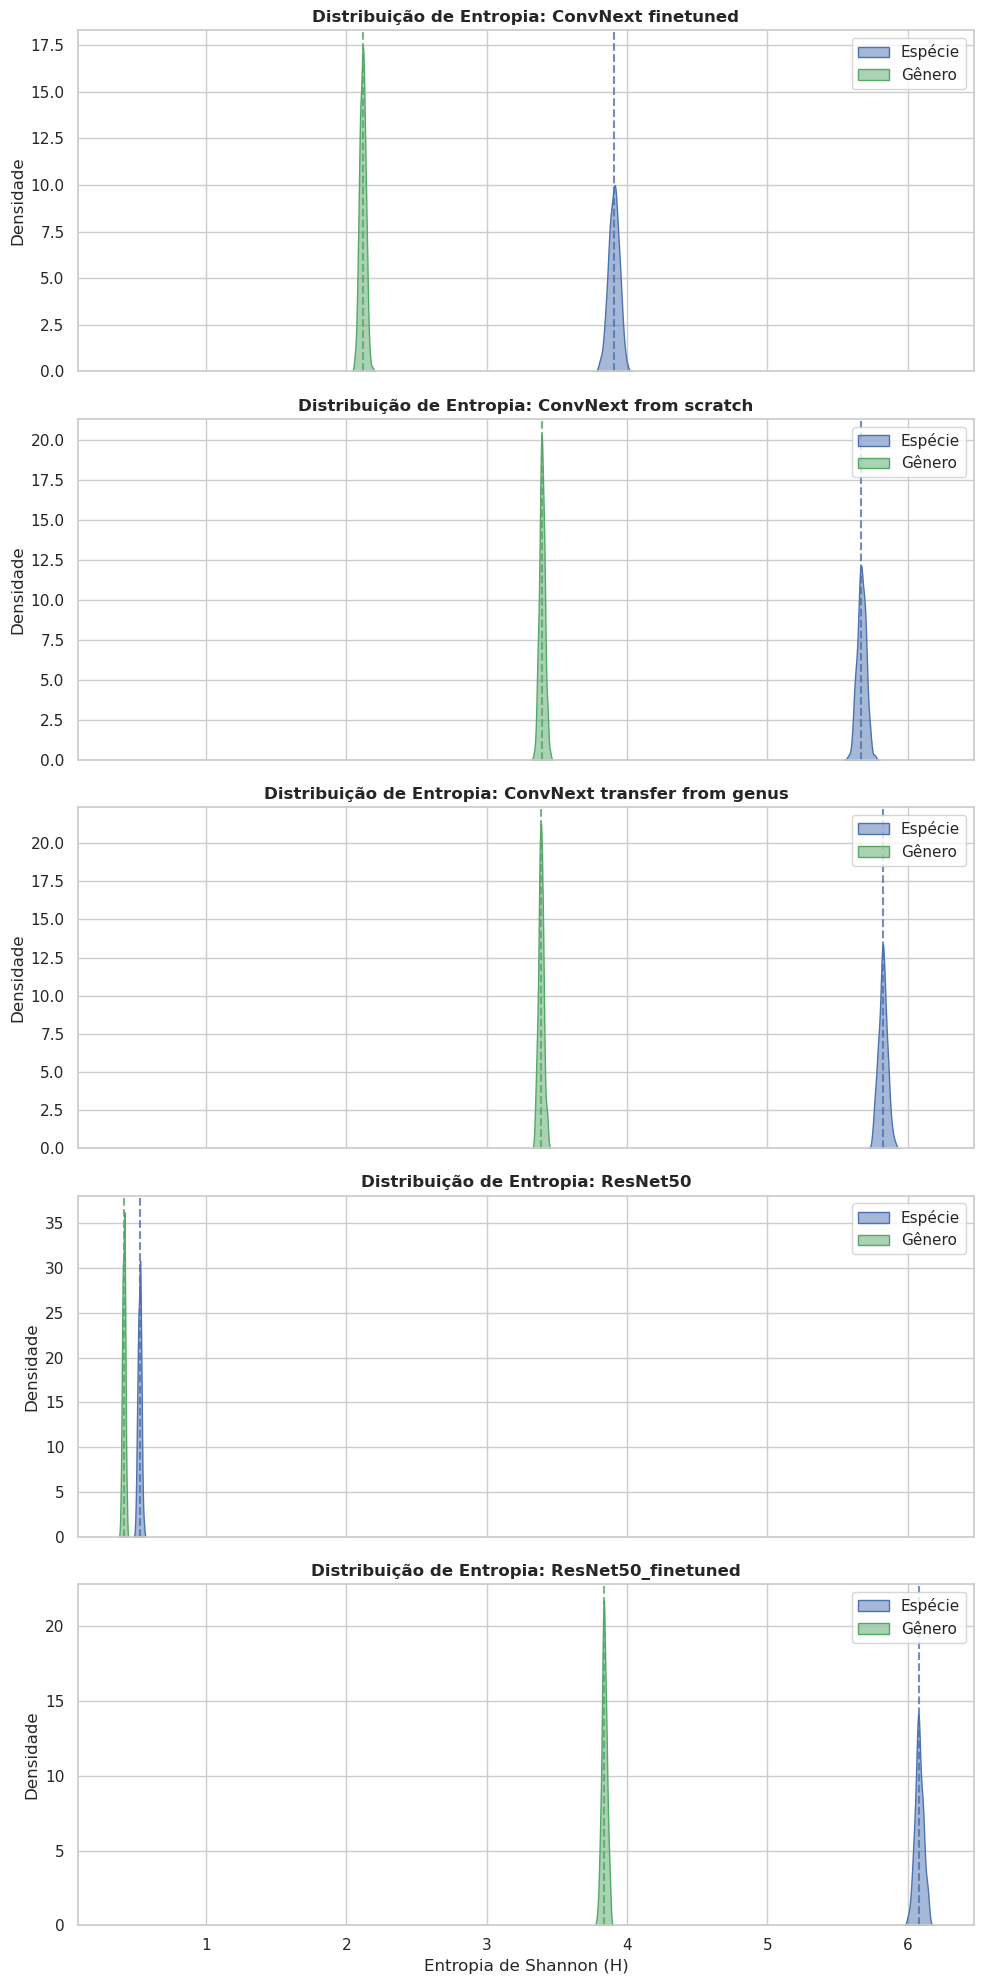

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

def plot_entropy_comparison(all_models_results):
    """
    all_models_results: Lista de dicionários contendo {'model': name, 'df': dataframe_do_modelo}
    """
    # 1. Preparar os dados para o Seaborn (formato 'long')
    plot_data = []
    for item in all_models_results:
        df_temp = item['df'].copy()
        df_temp['model'] = item['model']
        plot_data.append(df_temp)
    
    df_combined = pd.concat(plot_data)
    
    # 2. Configurar o estilo
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(len(all_models_results), 1, figsize=(10, 4 * len(all_models_results)), sharex=True)
    
    if len(all_models_results) == 1: axes = [axes]

    # 3. Plotar cada modelo em um subplot
    colors = ['#4C72B0', '#55A868'] # Azul para Espécie, Verde para Gênero
    
    for i, (ax, item) in enumerate(zip(axes, all_models_results)):
        model_name = item['model']
        subset = df_combined[df_combined['model'] == model_name]
        
        sns.kdeplot(data=subset, x='avg_h_species', ax=ax, fill=True, label='Espécie', color=colors[0], alpha=0.5)
        sns.kdeplot(data=subset, x='avg_h_genus', ax=ax, fill=True, label='Gênero', color=colors[1], alpha=0.5)
        
        # Adicionar linhas verticais para a média
        ax.axvline(subset['avg_h_species'].mean(), color=colors[0], linestyle='--', alpha=0.8)
        ax.axvline(subset['avg_h_genus'].mean(), color=colors[1], linestyle='--', alpha=0.8)
        
        ax.set_title(f'Distribuição de Entropia: {model_name}', fontweight='bold', fontsize=12)
        ax.set_ylabel('Densidade')
        ax.legend(loc='upper right')

    plt.xlabel('Entropia de Shannon (H)')
    plt.tight_layout()
    plt.savefig('comparativo_entropia_modelos.png', dpi=300)
    plt.show()


models_data = []
for model_dict in models:
    # Garantimos que 'df' seja um DataFrame real
    df_temp = pd.DataFrame(model_dict['results_entropy']) 
    models_data.append({
        'model': model_dict['model_name'], 
        'df': df_temp
    })

plot_entropy_comparison(models_data)

In [52]:
control_results = pd.read_parquet(
    "results_motifs_control/"
    "all_models_summary.parquet"
)

control_results[
    [
        "model_name",
        "motif",
        "n_sequences",
        "n_occurrences",
        "mean_motif_drop",
        "mean_random_drop",
        "mean_specific_drop",
        "p_value",
        "p_fdr",
        "significant_fdr"
    ]
].sort_values(
    "mean_specific_drop",
    ascending=False
).head(30)

,model_name,motif,n_sequences,n_occurrences,mean_motif_drop,mean_random_drop,mean_specific_drop,p_value,p_fdr,significant_fdr
215,ResNet50,GGGGGGG,13419,23877,0.365157,0.151151,0.214006,0.0,0.0,True
195,ResNet50,CCCCCCC,13688,24563,0.365544,0.154223,0.211321,0.0,0.0,True
214,ResNet50,GGGGGCG,19684,20863,0.417978,0.226474,0.191504,0.0,0.0,True
213,ResNet50,GGGGCGG,23115,24410,0.425107,0.239585,0.185523,0.0,0.0,True
179,ResNet50,AAATTTA,67476,72448,0.465848,0.286232,0.179617,0.0,0.0,True
239,ResNet50,TTTAAAA,82433,90748,0.463376,0.286880,0.176496,0.0,0.0,True
223,ResNet50,TAAATAT,60929,65320,0.453466,0.283596,0.169870,0.0,0.0,True
236,ResNet50,TTATATT,57111,61290,0.454735,0.288228,0.166508,0.0,0.0,True
212,ResNet50,GGGCGCG,26450,27863,0.400999,0.249380,0.151619,0.0,0.0,True
200,ResNet50,CGCGCGC,28461,35273,0.395556,0.247088,0.148468,0.0,0.0,True


In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_motif_vs_random(df, model_name):

    data = df[
        df["model_name"] == model_name
    ].copy()

    data["significance"] = np.where(
        data["significant_fdr"]
        & (data["mean_specific_drop"] > 0),
        "FDR significant",
        "Not significant"
    )

    fig, ax = plt.subplots(figsize=(7, 7))

    sns.scatterplot(
        data=data,
        x="mean_random_drop",
        y="mean_motif_drop",
        hue="significance",
        style="significance",
        s=70,
        alpha=0.8,
        ax=ax
    )

    min_v = min(
        data["mean_random_drop"].min(),
        data["mean_motif_drop"].min()
    )

    max_v = max(
        data["mean_random_drop"].max(),
        data["mean_motif_drop"].max()
    )

    ax.plot(
        [min_v, max_v],
        [min_v, max_v],
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        r"Matched random-region effect ($\Delta p_{\mathrm{random}}$)"
    )

    ax.set_ylabel(
        r"Learned-motif effect ($\Delta p_{\mathrm{motif}}$)"
    )

    ax.set_title(
        f"Learned Motif vs. Matched Random Perturbation\n{model_name}"
    )

    ax.grid(alpha=0.25)

    fig.tight_layout()
    plt.savefig(f'results_plots/motif_vs_random_{model_name}.png')
    plt.show()
    

In [66]:
def plot_specific_effect_significance(df, model_name):

    data = df[
        df["model_name"] == model_name
    ].copy()

    data = data[
        data["p_fdr"].notna()
    ].copy()

    data["neg_log10_fdr"] = (
        -np.log10(
            data["p_fdr"].clip(lower=1e-300)
        )
    )

    data["significant"] = (
        data["significant_fdr"]
        & (data["mean_specific_drop"] > 0)
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    sns.scatterplot(
        data=data,
        x="mean_specific_drop",
        y="neg_log10_fdr",
        hue="significant",
        s=70,
        alpha=0.8,
        ax=ax
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.axhline(
        -np.log10(0.05),
        linestyle="--",
        linewidth=1
    )

    ax.set_xlabel(
        r"Motif-specific effect ($\Delta p_{\mathrm{specific}}$)"
    )

    ax.set_ylabel(
        r"$-\log_{10}(p_{\mathrm{FDR}})$"
    )

    ax.set_title(
        f"Motif-Specific Effect and Statistical Evidence\n{model_name}"
    )

    fig.tight_layout()
    plt.savefig(f'results_plots/specific_effect_significance_{model_name}.png')
    plt.show()

In [67]:
def plot_effect_vs_support(df, model_name):

    data = df[
        (df["model_name"] == model_name)
        & (df["mean_specific_drop"] > 0)
    ].copy()

    fig, ax = plt.subplots(figsize=(8, 6))

    sns.scatterplot(
        data=data,
        x="n_sequences",
        y="mean_specific_drop",
        hue="significant_fdr",
        size="n_occurrences",
        sizes=(30, 200),
        alpha=0.75,
        ax=ax
    )

    ax.set_xscale("log")

    ax.set_xlabel(
        "Number of sequences containing the motif"
    )

    ax.set_ylabel(
        r"Motif-specific effect ($\Delta p_{\mathrm{specific}}$)"
    )

    ax.set_title(
        f"Motif Effect vs. Sequence Support\n{model_name}"
    )

    fig.tight_layout()
    plt.savefig(f'results_plots/effect_vs_support_{model_name}.png')
    plt.show()

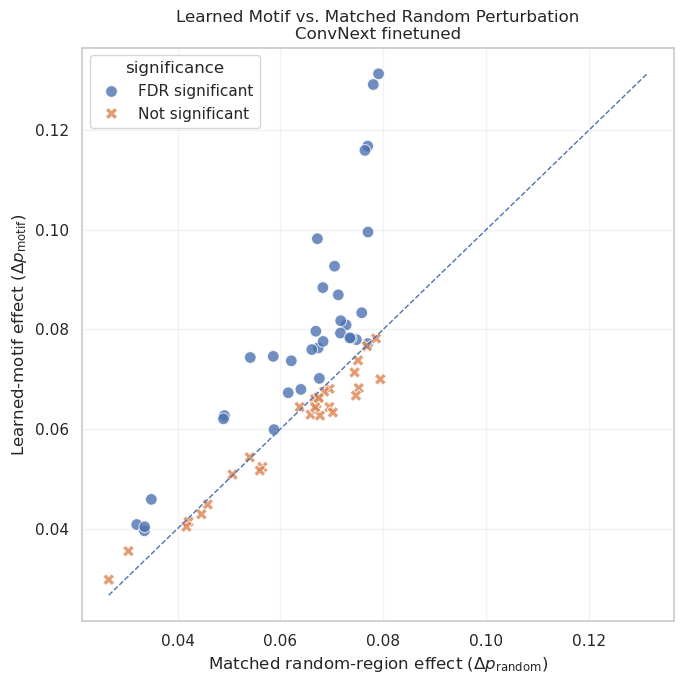

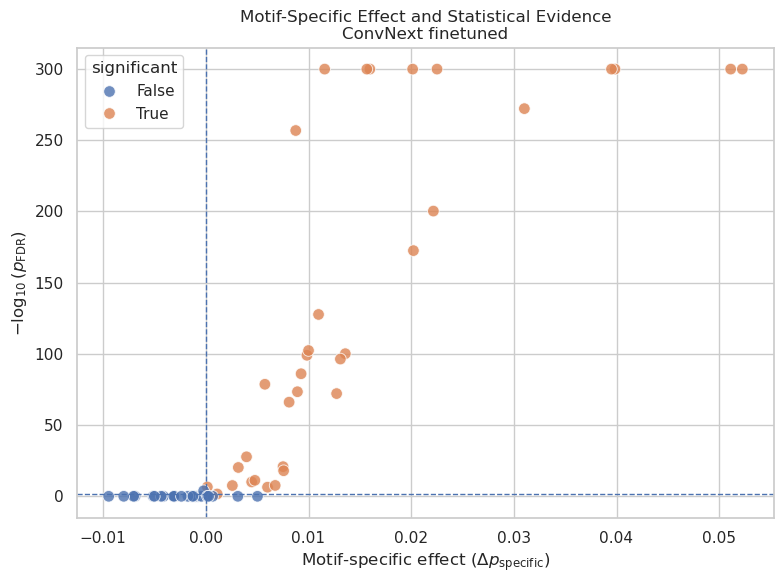

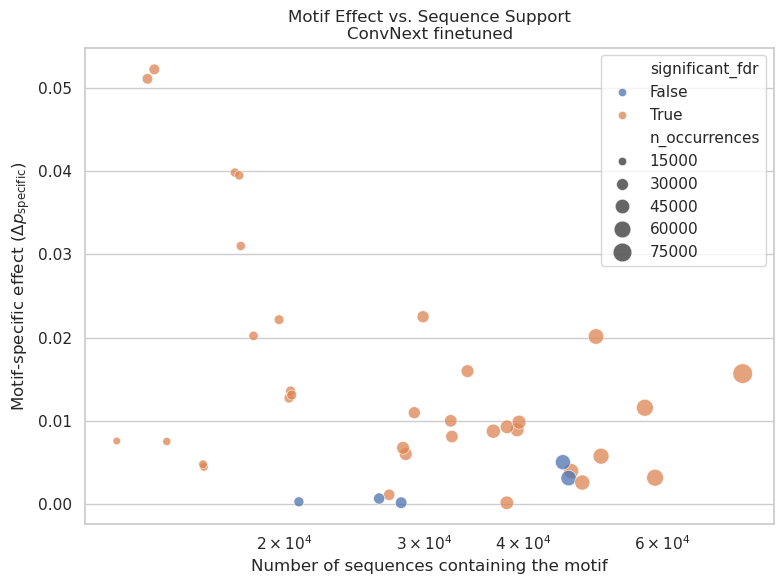

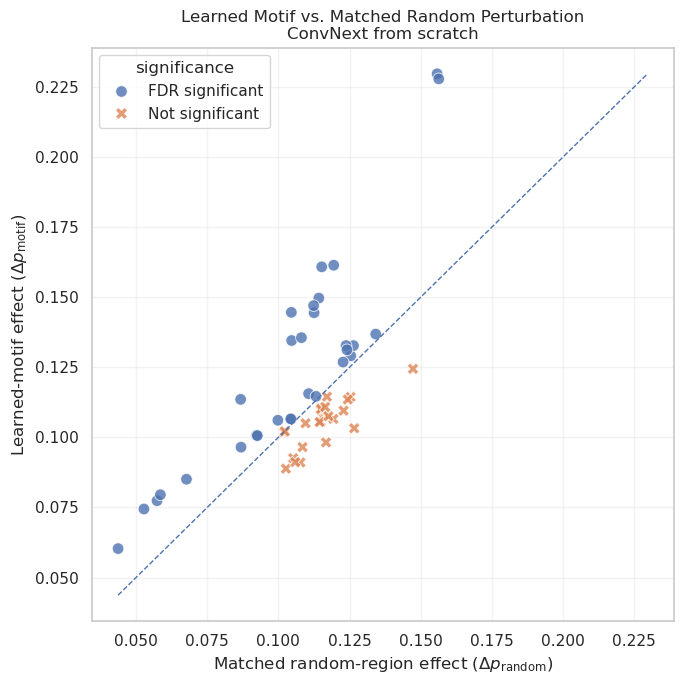

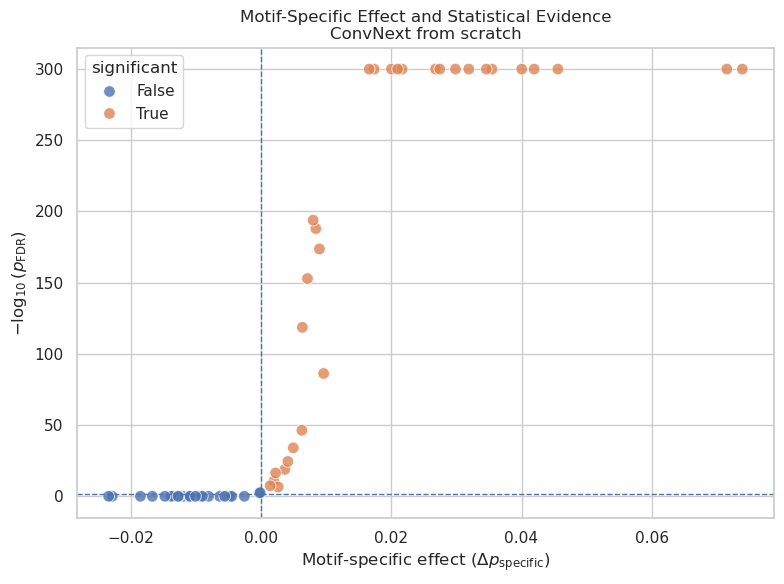

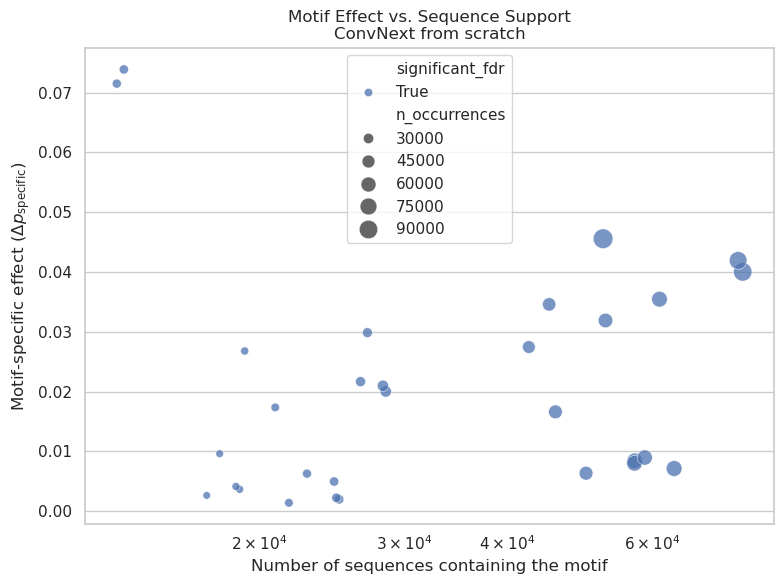

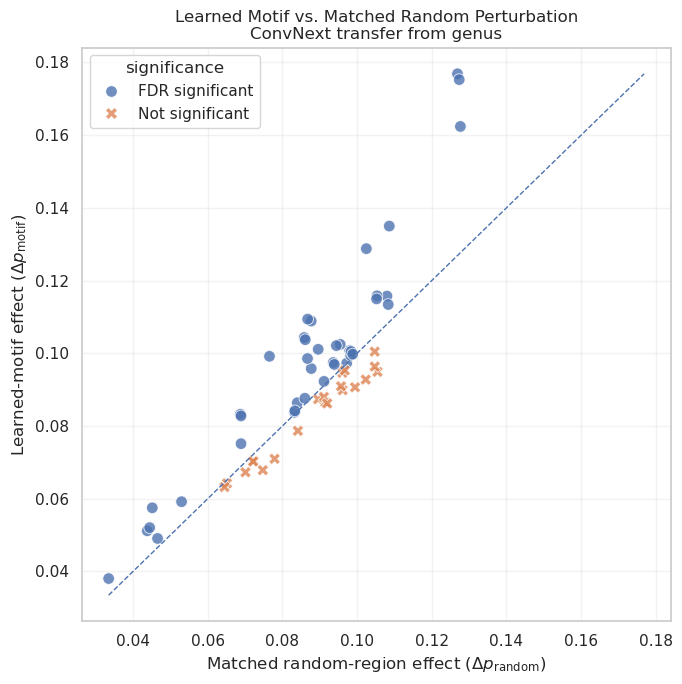

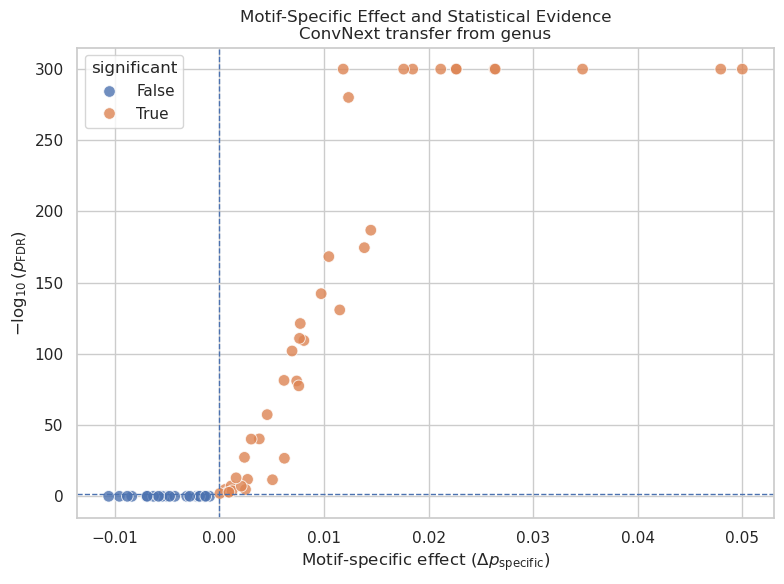

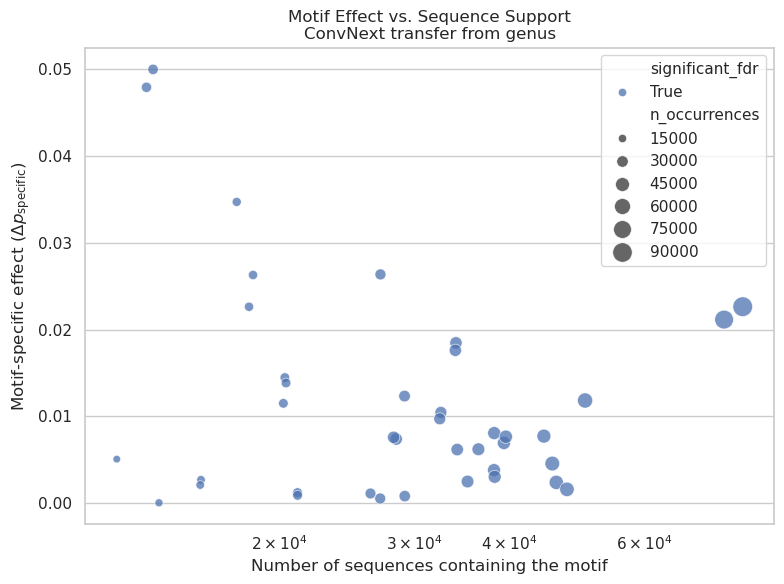

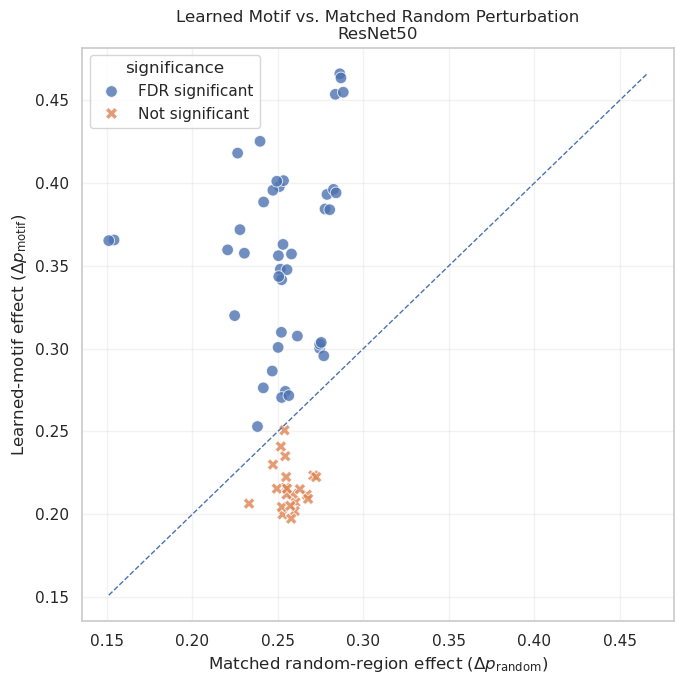

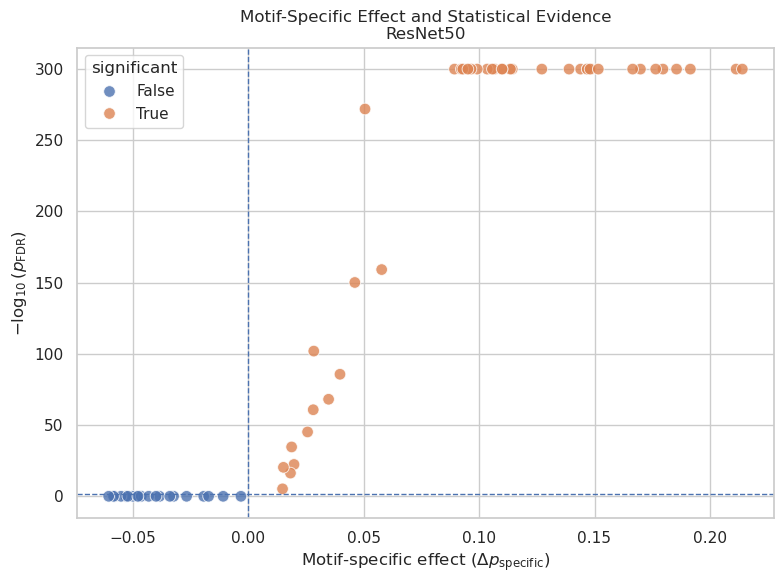

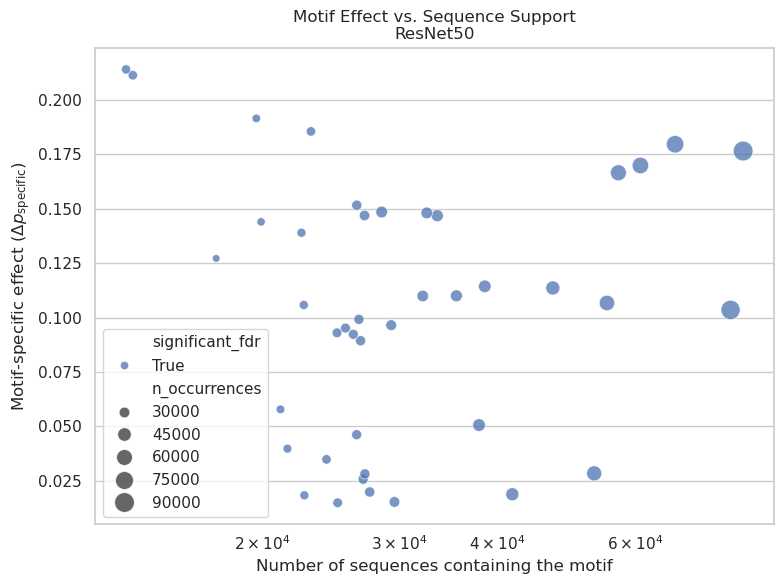

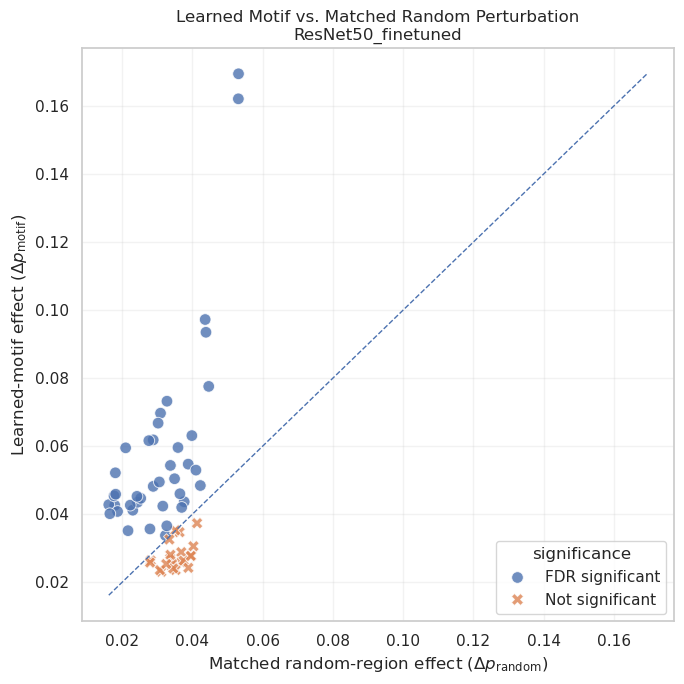

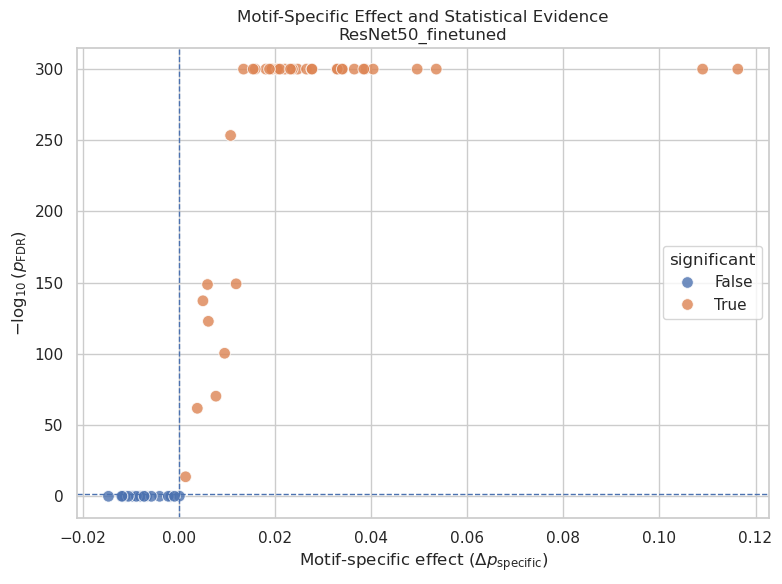

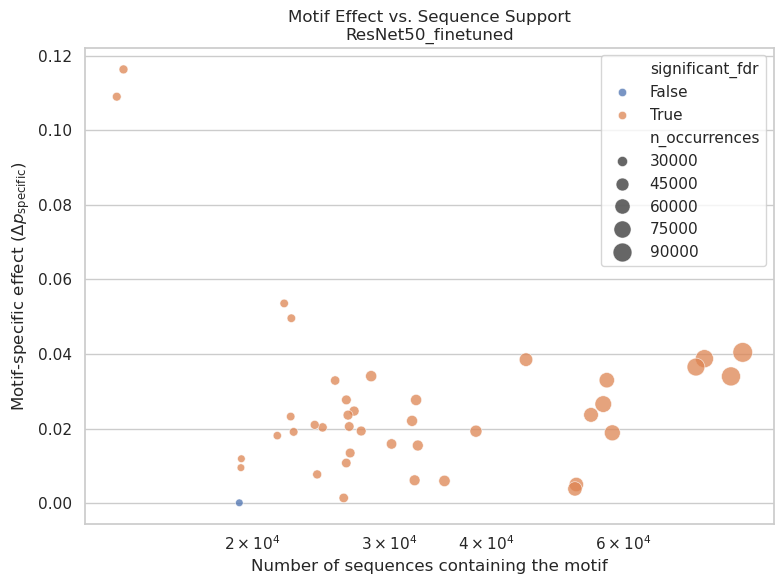

In [68]:
for model_dict in models:

    model_name = model_dict["model_name"]

    plot_motif_vs_random(
        control_results,
        model_name
    )

    plot_specific_effect_significance(
        control_results,
        model_name
    )

    plot_effect_vs_support(
        control_results,
        model_name
    )

In [60]:
import pandas as pd
import numpy as np

def build_motif_summary_table(
    models,
    target_coverage=0.75,
    min_sequences=5
):
    """
    Gera uma tabela-resumo dos motifs para cada modelo.

    Colunas:
    - Model
    - Extracted motifs
    - Validated motifs
    - Strongest motif
    - Top specific effect
    - Motifs for target cumulative effect coverage

    Validation criteria:
    - significant_fdr == True
    - mean_specific_drop > 0
    - n_sequences >= min_sequences
    """

    rows = []

    for model_dict in models:

        model_name = model_dict["model_name"]

        # DataFrame carregado anteriormente no notebook
        df = model_dict["motiffs_rel"].copy()

        # -----------------------------------------------------
        # 1. Número total de motifs extraídos
        # -----------------------------------------------------
        n_extracted = df["motif"].nunique()

        # -----------------------------------------------------
        # 2. Motifs estatisticamente validados
        # -----------------------------------------------------
        df_valid = df[
            (df["significant_fdr"] == True)
            & (df["mean_specific_drop"] > 0)
            & (df["n_sequences"] >= min_sequences)
        ].copy()

        n_validated = df_valid["motif"].nunique()

        # Caso nenhum motif tenha sido validado
        if df_valid.empty:

            rows.append({
                "Model": model_name,
                "Extracted motifs": n_extracted,
                "Validated motifs": 0,
                "Strongest motif": np.nan,
                "Top specific effect": np.nan,
                "Motifs for 75% effect": np.nan,
                "Actual coverage": np.nan
            })

            continue

        # -----------------------------------------------------
        # 3. Ordenar por efeito específico
        # -----------------------------------------------------
        df_valid = (
            df_valid
            .sort_values(
                "mean_specific_drop",
                ascending=False
            )
            .reset_index(drop=True)
        )

        # -----------------------------------------------------
        # 4. Motif com maior efeito específico
        # -----------------------------------------------------
        strongest = df_valid.iloc[0]

        strongest_motif = strongest["motif"]
        strongest_effect = strongest["mean_specific_drop"]

        # -----------------------------------------------------
        # 5. Contribuição cumulativa
        # -----------------------------------------------------
        total_effect = df_valid[
            "mean_specific_drop"
        ].sum()

        df_valid["relative_effect"] = (
            df_valid["mean_specific_drop"]
            / total_effect
        )

        df_valid["cumulative_effect"] = (
            df_valid["relative_effect"]
            .cumsum()
        )

        # -----------------------------------------------------
        # 6. Número mínimo de motifs necessário para atingir
        #    target_coverage (ex.: 75%)
        # -----------------------------------------------------
        reached = np.where(
            df_valid["cumulative_effect"].values
            >= target_coverage
        )[0]

        if len(reached) > 0:
            n_for_coverage = int(reached[0] + 1)

            actual_coverage = float(
                df_valid.loc[
                    n_for_coverage - 1,
                    "cumulative_effect"
                ]
            )
        else:
            n_for_coverage = len(df_valid)
            actual_coverage = float(
                df_valid["cumulative_effect"].iloc[-1]
            )

        # -----------------------------------------------------
        # 7. Salvar resumo
        # -----------------------------------------------------
        rows.append({
            "Model": model_name,
            "Extracted motifs": n_extracted,
            "Validated motifs": n_validated,
            "Strongest motif": strongest_motif,
            "Top specific effect": strongest_effect,
            "Top motif N sequences": int(strongest["n_sequences"]),
            "Top motif pFDR": strongest["p_fdr"],
            "Motifs for 75% effect": n_for_coverage,
            "Actual coverage": actual_coverage
        })

    summary_df = pd.DataFrame(rows)

    return summary_df

In [61]:
motif_summary = build_motif_summary_table(
    models,
    target_coverage=0.75,
    min_sequences=5
)

display(motif_summary)

,Model,Extracted motifs,Validated motifs,Strongest motif,Top specific effect,Top motif N sequences,Top motif pFDR,Motifs for 75% effect,Actual coverage
0,ConvNext finetuned,63,34,CCCCCCC,0.052251,13688,0.0,15,0.761156
1,ConvNext from scratch,54,30,CCCCCCC,0.073902,13688,0.0,12,0.761337
2,ConvNext transfer from genus,61,40,CCCCCCC,0.049990,13688,0.0,15,0.760958
3,ResNet50,64,42,GGGGGGG,0.214006,13419,0.0,22,0.756039
4,ResNet50_finetuned,62,40,CCCCCCC,0.116315,13688,0.0,20,0.755384


In [62]:
motif_summary_formatted = motif_summary.copy()

motif_summary_formatted["Top specific effect"] = (
    motif_summary_formatted["Top specific effect"]
    .map(lambda x: f"{x:.4f}")
)

motif_summary_formatted["Actual coverage"] = (
    motif_summary_formatted["Actual coverage"]
    .map(lambda x: f"{x * 100:.1f}%")
)

display(motif_summary_formatted)

,Model,Extracted motifs,Validated motifs,Strongest motif,Top specific effect,Top motif N sequences,Top motif pFDR,Motifs for 75% effect,Actual coverage
0,ConvNext finetuned,63,34,CCCCCCC,0.0523,13688,0.0,15,76.1%
1,ConvNext from scratch,54,30,CCCCCCC,0.0739,13688,0.0,12,76.1%
2,ConvNext transfer from genus,61,40,CCCCCCC,0.0500,13688,0.0,15,76.1%
3,ResNet50,64,42,GGGGGGG,0.2140,13419,0.0,22,75.6%
4,ResNet50_finetuned,62,40,CCCCCCC,0.1163,13688,0.0,20,75.5%


In [63]:
latex_table = motif_summary[
    [
        "Model",
        "Extracted motifs",
        "Validated motifs",
        "Strongest motif",
        "Top specific effect",
        "Motifs for 75% effect"
    ]
].to_latex(
    index=False,
    escape=False,
    float_format="%.4f",
    caption=(
        "Summary of statistically validated first-layer motifs "
        "and motif-specific perturbation effects."
    ),
    label="tab:motif_specific_summary"
)

print(latex_table)

\begin{table}
\caption{Summary of statistically validated first-layer motifs and motif-specific perturbation effects.}
\label{tab:motif_specific_summary}
\begin{tabular}{lrrlrr}
\toprule
Model & Extracted motifs & Validated motifs & Strongest motif & Top specific effect & Motifs for 75% effect \\
\midrule
ConvNext finetuned & 63 & 34 & CCCCCCC & 0.0523 & 15 \\
ConvNext from scratch & 54 & 30 & CCCCCCC & 0.0739 & 12 \\
ConvNext transfer from genus & 61 & 40 & CCCCCCC & 0.0500 & 15 \\
ResNet50 & 64 & 42 & GGGGGGG & 0.2140 & 22 \\
ResNet50_finetuned & 62 & 40 & CCCCCCC & 0.1163 & 20 \\
\bottomrule
\end{tabular}
\end{table}



In [69]:
import pandas as pd
import numpy as np


def build_supplementary_motif_table(
    models,
    min_sequences=5
):
    """
    Build Supplementary Table containing all statistically
    validated motifs from all models.

    Validation criteria:
      - significant_fdr == True
      - mean_specific_drop > 0
      - n_sequences >= min_sequences

    Motifs are ranked independently within each model by
    mean_specific_drop.
    """

    all_tables = []

    for model_dict in models:

        model_name = model_dict["model_name"]
        df = model_dict["motiffs_rel"].copy()

        # -----------------------------------------------------
        # Keep statistically validated motifs only
        # -----------------------------------------------------
        df_valid = df[
            (df["significant_fdr"] == True)
            & (df["mean_specific_drop"] > 0)
            & (df["n_sequences"] >= min_sequences)
        ].copy()

        if df_valid.empty:
            continue

        # -----------------------------------------------------
        # Rank motifs by specific effect
        # -----------------------------------------------------
        df_valid = (
            df_valid
            .sort_values(
                "mean_specific_drop",
                ascending=False
            )
            .reset_index(drop=True)
        )

        df_valid["Rank"] = np.arange(
            1,
            len(df_valid) + 1
        )

        df_valid["Model"] = model_name

        # -----------------------------------------------------
        # Select manuscript-relevant columns
        # -----------------------------------------------------
        df_valid = df_valid[
            [
                "Model",
                "Rank",
                "motif",
                "n_sequences",
                "n_occurrences",
                "mean_motif_drop",
                "mean_random_drop",
                "mean_specific_drop",
                "p_value",
                "p_fdr"
            ]
        ]

        # Rename for final table
        df_valid = df_valid.rename(
            columns={
                "motif": "Motif",
                "n_sequences": "N sequences",
                "n_occurrences": "N occurrences",
                "mean_motif_drop": "Mean motif drop",
                "mean_random_drop": "Mean random drop",
                "mean_specific_drop": "Mean specific drop",
                "p_value": "p-value",
                "p_fdr": "p-FDR"
            }
        )

        all_tables.append(df_valid)

    supplementary_df = pd.concat(
        all_tables,
        ignore_index=True
    )

    return supplementary_df

In [70]:
supp_motifs = build_supplementary_motif_table(
    models,
    min_sequences=5
)

display(supp_motifs)

,Model,Rank,Motif,N sequences,N occurrences,Mean motif drop,Mean random drop,Mean specific drop,p-value,p-FDR
0,ConvNext finetuned,1,CCCCCCC,13688,24563,0.131354,0.079103,0.052251,0.000000e+00,0.000000e+00
1,ConvNext finetuned,2,GGGGGGG,13419,23877,0.129197,0.078078,0.051119,0.000000e+00,0.000000e+00
2,ConvNext finetuned,3,GGGGGGA,17305,18056,0.116833,0.076986,0.039847,0.000000e+00,0.000000e+00
3,ConvNext finetuned,4,TCCCCCC,17531,18248,0.115967,0.076457,0.039509,0.000000e+00,0.000000e+00
4,ConvNext finetuned,5,GGGGCCC,17608,18309,0.098218,0.067195,0.031023,9.258749e-274,5.833012e-273
...,...,...,...,...,...,...,...,...,...,...
181,ResNet50_finetuned,36,GAGAGGA,32362,33366,0.048417,0.042245,0.006172,7.635386e-124,1.314983e-123
182,ResNet50_finetuned,37,TCGAAAA,35349,36225,0.043647,0.037649,0.005998,1.043287e-149,1.902465e-149
183,ResNet50_finetuned,38,TTTTCTC,52193,54408,0.041980,0.036940,0.005041,2.978183e-138,5.275639e-138
184,ResNet50_finetuned,39,TTTTGCT,51976,54151,0.036564,0.032695,0.003868,9.778565e-63,1.554541e-62


In [71]:
print(
    supp_motifs
    .groupby("Model")
    .size()
)

Model
ConvNext finetuned              34
ConvNext from scratch           30
ConvNext transfer from genus    40
ResNet50                        42
ResNet50_finetuned              40
dtype: int64


In [72]:
supp_motifs.to_csv(
    "Supplementary_Table_S1_Validated_Motifs.csv",
    index=False
)

In [74]:
supp_motifs_display = supp_motifs.copy()

for col in [
    "Mean motif drop",
    "Mean random drop",
    "Mean specific drop"
]:
    supp_motifs_display[col] = (
        supp_motifs_display[col]
        .map(lambda x: f"{x:.6f}")
    )

for col in [
    "p-value",
    "p-FDR"
]:
    supp_motifs_display[col] = (
        supp_motifs_display[col]
        .map(
            lambda x:
            f"{x:.3e}"
            if pd.notna(x)
            else ""
        )
    )

display(supp_motifs_display)

latex_supp = supp_motifs_display.to_latex(
    index=False,
    escape=False,
    longtable=True,
    caption=(
        "Statistically validated first-layer CNN motifs and "
        "their matched perturbation effects. Motifs are ranked "
        "within each model according to the mean motif-specific "
        "probability drop."
    ),
    label="tab:supp_validated_motifs",
    column_format="lllr r r r r r r"
)

with open(
    "Supplementary_Table_S1_Validated_Motifs.tex",
    "w"
) as f:
    f.write(latex_supp)

,Model,Rank,Motif,N sequences,N occurrences,Mean motif drop,Mean random drop,Mean specific drop,p-value,p-FDR
0,ConvNext finetuned,1,CCCCCCC,13688,24563,0.131354,0.079103,0.052251,0.000e+00,0.000e+00
1,ConvNext finetuned,2,GGGGGGG,13419,23877,0.129197,0.078078,0.051119,0.000e+00,0.000e+00
2,ConvNext finetuned,3,GGGGGGA,17305,18056,0.116833,0.076986,0.039847,0.000e+00,0.000e+00
3,ConvNext finetuned,4,TCCCCCC,17531,18248,0.115967,0.076457,0.039509,0.000e+00,0.000e+00
4,ConvNext finetuned,5,GGGGCCC,17608,18309,0.098218,0.067195,0.031023,9.259e-274,5.833e-273
...,...,...,...,...,...,...,...,...,...,...
181,ResNet50_finetuned,36,GAGAGGA,32362,33366,0.048417,0.042245,0.006172,7.635e-124,1.315e-123
182,ResNet50_finetuned,37,TCGAAAA,35349,36225,0.043647,0.037649,0.005998,1.043e-149,1.902e-149
183,ResNet50_finetuned,38,TTTTCTC,52193,54408,0.041980,0.036940,0.005041,2.978e-138,5.276e-138
184,ResNet50_finetuned,39,TTTTGCT,51976,54151,0.036564,0.032695,0.003868,9.779e-63,1.555e-62
